[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture3_notebook.ipynb)

# Blockchain Applications — Lecture 3: Crypto Indices: CRIX, VCRIX and Investible Index Funds

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

This notebook reproduces the computations of Lecture 3 in the order of the slides: concentration and survivorship
bias, the construction of CRIX (Laspeyres index, divisor, liquidity rule, number of constituents by the Akaike
information criterion, smoothed over six months), our own CRIX-style replica on ten coins compared with the published
index, the real CRIX 2017–2026, the volatility index VCRIX with a GARCH(1,1) and a HAR model, the tracking of a spot
Bitcoin exchange-traded fund, and two other types of crypto indices rebuilt on our data (square-root weights and a
Bitcoin-and-cash index with a protection floor).

Data (all in the `data/` folder of the course repository, real data only):
- `indices/crix_daily.csv`, `indices/vcrix_daily.csv`: Royalton CRIX (6 September 2017 – 6 November 2026) and VCRIX
  (4 January 2018 – 6 November 2026), daily, read from the chart data of [thecrix.de](https://www.thecrix.de) on
  7 November 2026;
- `indices/coin_supply_coinmetrics.csv`: current supply (`SplyCur`) of ten coins, from the
  [Coin Metrics Community API](https://docs.coinmetrics.io/api/v4);
- `market/<coin>-USD.CC.csv`: EODHD daily prices and USD volumes of Bitcoin, Ethereum, Dogecoin, Cardano, Litecoin,
  Bitcoin Cash, Ethereum Classic, Monero, Dash (`DASH-USD.CC`) and Zcash (`ZEC-USD.CC`), to 30 October 2026;
  `market/IBIT.US.csv`: the iShares Bitcoin Trust ETF (EODHD);
- `hourly/BTC-USD.CC_1h.csv`: EODHD hourly Bitcoin prices, used for the price at 16:00 New York time;
- `indices/fed_funds_effective_daily_fred.csv`: effective federal funds rate, daily, from
  [FRED](https://fred.stlouisfed.org/series/DFF) (series DFF).

The quarterly AIC rule fits many small least-squares problems; the whole notebook runs in about a minute.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_3'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

In [2]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

## Setup: packages, chart style and data

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## 1. Common code: data, the index engine and the rule for the number of constituents

The next cell reads the data and defines the functions used in the rest of the notebook:

- `index_series(name)`: CRIX or VCRIX on the daily calendar; missing days stay missing, and `logret()` computes
  daily log returns in %, $r_t = 100(\ln I_t - \ln I_{t-1})$, only between consecutive days;
- `coin_panel()`: prices $P_{it}$, USD volumes and market values $\mathrm{MV}_{it} = P_{it}\,Q_{it}$ (billion USD) of
  the ten coins, with $Q_{it}$ the Coin Metrics current supply;
- `laspeyres(schedule, cap)`: the market-value Laspeyres index with a divisor (Section 3);
- `rule_rows`, `resid`, `kde_loglik`, `aic_curve`, `first_rise`, `smooth_choice`: the rule for the number of
  constituents (Section 3);
- `eligible(tau)`: the liquidity rule, ADTV over the last 90 days at least the 25th percentile of the ADTVs.

`RES` collects the numbers quoted on the slides.

In [5]:
import matplotlib
import matplotlib.dates
from scipy import stats
from scipy.optimize import least_squares
import statsmodels.api as sm

def fix_years(fig):
    # year ticks that do not overlap: every second year on narrow date axes, every year on wide ones
    for a in fig.axes:
        loc = a.xaxis.get_major_locator()
        if not isinstance(loc, matplotlib.dates.DateLocator) or isinstance(loc, matplotlib.dates.MonthLocator):
            continue
        lo, hi = a.get_xlim()
        if hi - lo < 3 * 365:
            continue
        w = a.get_position().width
        a.xaxis.set_major_locator(matplotlib.dates.YearLocator(1 if w > 0.6 else 2))
        a.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y'))


RES = {}                                   # numbers quoted on the slides
END_R = '2026-10-30'                       # last day with prices of all ten coins (EODHD)
OFFICIAL = '2018-03-16'                    # official CRIX history starts on 16 March 2018 (royalton-partners.com)
COINS = ['BTC', 'ETH', 'DOGE', 'ADA', 'LTC', 'BCH', 'ETC', 'XMR', 'DASH', 'ZEC']
CNAME = {'BTC': 'Bitcoin', 'ETH': 'Ethereum', 'DOGE': 'Dogecoin', 'ADA': 'Cardano', 'LTC': 'Litecoin',
         'BCH': 'Bitcoin Cash', 'ETC': 'Ethereum Classic', 'XMR': 'Monero', 'DASH': 'Dash', 'ZEC': 'Zcash'}
CCOL = {'BTC': BTC, 'ETH': ETH, 'DOGE': GOLD, 'ADA': GREEN, 'LTC': TEAL, 'BCH': ORANGE, 'ETC': '#556B2F',
        'XMR': RED, 'DASH': BLUE, 'ZEC': '#D63384'}


def index_series(name):
    # Royalton CRIX or VCRIX, daily (thecrix.de); missing days stay missing (NaN) on the daily calendar
    s = pd.read_csv(data_file('indices', f'{name}_daily.csv'), parse_dates=['date']).set_index('date').iloc[:, 0]
    return s.reindex(pd.date_range(s.index[0], s.index[-1]))


def logret(s):
    # daily log returns in %, only between two consecutive calendar days (a return over a data gap is dropped)
    return 100 * np.log(s).diff()


def market_file(sym):
    return pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')


def coin_panel(start='2017-06-01', end=END_R):
    # daily prices (USD), volumes (USD) and market values (billion USD = price x Coin Metrics current supply)
    days = pd.date_range(start, end)
    px, vol = {}, {}
    for c in COINS:
        d = market_file(f'{c}-USD.CC')
        d = d[d['close'] > 0]
        px[c], vol[c] = d['close'].reindex(days), d['volume'].reindex(days)
    px, vol = pd.DataFrame(px), pd.DataFrame(vol)
    sup = pd.read_csv(data_file('indices', 'coin_supply_coinmetrics.csv'), parse_dates=['date']).set_index('date')
    sup = sup[COINS].reindex(days).ffill(limit=3)
    return px, vol, sup, px * sup / 1e9


PX, VOL, SUP, MV = coin_panel()


def month_ends(start, end=END_R):
    return [d for d in pd.date_range(start, end, freq='ME')]


def laspeyres(schedule, cap=None, base=1000.0):
    # Market-value Laspeyres index with a divisor. schedule: list of (tau, members) with tau a rebalancing day; between
    # rebalancing days the quantities Q_i (supply at tau, times the cap factor AW_i) are fixed:
    #   I_t = sum_i P_it Q_i / D_tau,  D_tau chosen so that the index does not jump at tau.
    # cap: maximum weight of one constituent at tau (excess shared pro rata by the others).
    level, divisor, weights = {}, {}, {}
    I_prev, D = base, None
    for j, (tau, mem) in enumerate(schedule):
        end_ = schedule[j + 1][0] if j + 1 < len(schedule) else pd.Timestamp(END_R)
        mv0 = MV.loc[tau, mem].dropna()
        mem = list(mv0.index)
        w = mv0 / mv0.sum()
        if cap is not None and len(w) > 1:
            for _ in range(50):                 # iterate: capping one weight may push another above the cap
                over = w > cap
                if not over.any():
                    break
                excess = (w[over] - cap).sum()
                w[over] = cap
                w[~over] += excess * w[~over] / w[~over].sum()
        q = (w * mv0.sum() * 1e9 / PX.loc[tau, mem])            # quantities: capped weight x total value / price
        D = float((PX.loc[tau, mem] * q).sum() / I_prev)        # new divisor: the index level at tau is unchanged
        days = pd.date_range(tau + pd.Timedelta(days=1), end_)
        val = (PX.loc[days, mem] * q).sum(axis=1, min_count=len(mem)) / D
        for t in days:
            level[t] = val.loc[t]
        divisor[tau] = D
        weights[tau] = w
        I_prev = float(val.dropna().iloc[-1]) if val.notna().any() else I_prev
    lev = pd.Series(level).sort_index()
    lev.loc[schedule[0][0]] = base
    return lev.sort_index(), pd.Series(divisor), pd.DataFrame(weights).T.reindex(columns=COINS).fillna(0)


def ann_stats(lvl, per=365):
    # CAGR, annualised volatility of daily log returns, maximum drawdown (with dates) of an index level series
    s = lvl.dropna()
    yrs = (s.index[-1] - s.index[0]).days / 365.25
    r = logret(lvl).dropna()
    dd = s / s.cummax() - 1
    tr = dd.idxmin(); pk = s.loc[:tr].idxmax()
    return dict(start=f'{s.index[0]:%Y-%m-%d}', end=f'{s.index[-1]:%Y-%m-%d}', years=yrs, first=float(s.iloc[0]), last=float(s.iloc[-1]),
                cagr=100 * ((s.iloc[-1] / s.iloc[0]) ** (1 / yrs) - 1), vol=float(r.std() * np.sqrt(per)), n=len(r),
                mdd=100 * float(dd.min()), mdd_peak=f'{pk:%Y-%m-%d}', mdd_trough=f'{tr:%Y-%m-%d}')


# ---------- the rule for the number of constituents (Trimborn & Hardle, 2018; smoothed over six months)
def rule_rows(days, mem):
    # for each day of the window: log return of the total market index (TMI, all members) and the arrays needed for
    # the candidate indices; quantities = supply at the end of the previous month, members ordered by market value
    rows = []
    for t in days:
        tau = t.to_period('M').start_time - pd.Timedelta(days=1)
        order = MV.loc[tau, mem].sort_values(ascending=False).index.tolist()
        q = SUP.loc[tau, order].values
        p1, p0 = PX.loc[t, order].values, PX.loc[t - pd.Timedelta(days=1), order].values
        if np.isfinite(p1).all() and np.isfinite(p0).all() and np.isfinite(q).all():
            rows.append((q, p1, p0))
    return rows


def resid(rows, k, beta):
    # eps_t(k, beta) = r_TMI,t - r_CRIX(k,beta),t : first coin with weight 1, the next k-1 with free weights beta
    e = np.empty(len(rows))
    for j, (q, p1, p0) in enumerate(rows):
        tot = np.log((p1 * q).sum() / (p0 * q).sum())
        w = np.concatenate([[1.0], beta, np.zeros(len(q) - k)])
        a1, a0 = (w * p1 * q).sum(), (w * p0 * q).sum()
        e[j] = tot - np.log(a1 / a0) if a1 > 0 and a0 > 0 else 1.0
    return e


def kde_loglik(base, x, loo=False):
    # log-likelihood of x under the Gaussian kernel density of the base residuals (Silverman bandwidth);
    # loo=True: leave-one-out (x is the base sample itself)
    n = len(base)
    h = 0.9 * min(base.std(ddof=1), stats.iqr(base) / 1.349) * n ** (-0.2)
    u = (x[:, None] - base[None, :]) / h
    K = np.exp(-0.5 * u ** 2) / np.sqrt(2 * np.pi)
    if loo:
        np.fill_diagonal(K, 0.0)
        f = K.sum(axis=1) / ((n - 1) * h)
    else:
        f = K.mean(axis=1) / h
    return float(np.log(np.maximum(f, 1e-300)).sum()), h


def aic_curve(days, mem, kmax=None):
    # AIC(k) = -2 log L(k) + 2 (k - 1), k = 1..kmax; L(k): the base density (k = 1, leave-one-out) at eps(k, beta_hat)
    rows = rule_rows(days, mem)
    kmax = kmax or len(mem)
    base = resid(rows, 1, np.array([]))
    ll1, h = kde_loglik(base, base, loo=True)
    aic = {1: -2 * ll1}
    for k in range(2, kmax + 1):
        fit = least_squares(lambda b: resid(rows, k, b), np.ones(k - 1), bounds=(0, np.inf))
        ll, _ = kde_loglik(base, resid(rows, k, fit.x))
        aic[k] = -2 * ll + 2 * (k - 1)
    return pd.Series(aic), len(rows), h


def first_rise(aic):
    # ECRIX rule: stop at the first k whose AIC is above that of k - 1
    ks = list(aic.index)
    for a, b in zip(ks[:-1], ks[1:]):
        if aic[b] > aic[a]:
            return a
    return ks[-1]


def smooth_choice(curves):
    # smoothed rule: pool the AIC curves of the last six months, fit polynomials of degree 1..dmax in k,
    # keep the degree with the lowest (Gaussian) AIC of the fit, choose the k that minimises the fitted polynomial
    k = np.concatenate([c.index.values for c in curves]).astype(float)
    y = np.concatenate([c.values for c in curves])
    kmax = int(k.max())
    best = None
    for d in range(1, min(20, kmax - 2) + 1):
        X = np.vander((k - k.mean()) / k.std(), d + 1)
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        rss = ((y - X @ b) ** 2).sum()
        a = len(y) * np.log(rss / len(y)) + 2 * (d + 1)
        if best is None or a < best[0]:
            best = (a, d, b)
    grid = np.arange(1, kmax + 1, dtype=float)
    fitted = np.vander((grid - k.mean()) / k.std(), best[1] + 1) @ best[2]
    return int(grid[np.argmin(fitted)]), best[1], pd.Series(fitted, index=grid.astype(int))


def eligible(tau, window=90):
    # liquidity rule: average daily traded volume (ADTV, USD) over the last `window` days at least the 25th percentile of
    # the ADTVs of all coins of the universe with full data in the window
    w = pd.date_range(tau - pd.Timedelta(days=window - 1), tau)
    ok = [c for c in COINS if PX.loc[w, c].notna().all() and SUP.loc[w, c].notna().all()]
    adtv = VOL.loc[w, ok].mean()
    thr = adtv.quantile(0.25)
    return [c for c in ok if adtv[c] >= thr], adtv, thr

## 2. Motivation for a crypto index

### 2.1 How concentrated is the market?

Value shares $w_i = M_i / \sum_j M_j$ of the ten coins, the Herfindahl–Hirschman index and the effective number of
coins:

$$ \mathrm{HHI} = \sum_{i=1}^{N} w_i^2, \qquad N_{\text{eff}} = 1/\mathrm{HHI}. $$

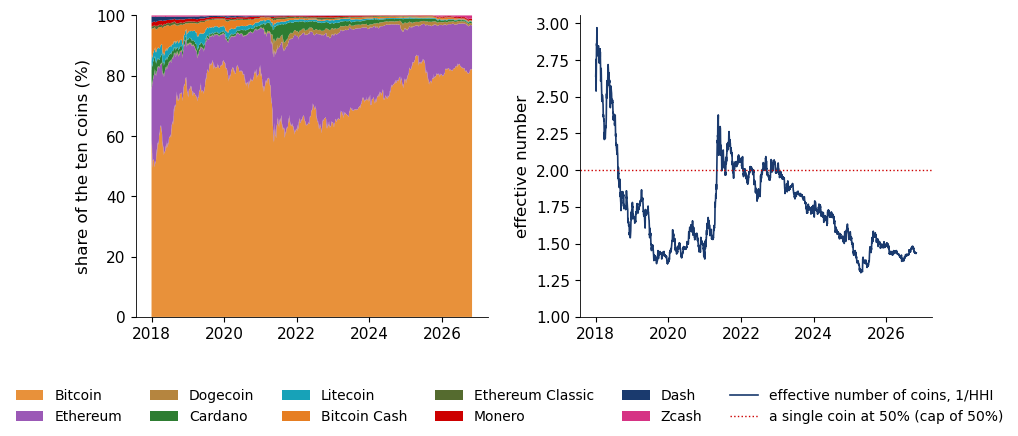

{'start': '2018-01-01', 'end': '2026-10-30', 'btc_first': np.float64(57.308), 'btc_last': np.float64(82.152), 'btc_min': 49.575, 'btc_min_date': '2018-01-14', 'btc_max': 87.14, 'btc_max_date': '2025-04-21', 'eth_last': np.float64(14.492), 'top2_last': np.float64(96.644), 'hhi_last': np.float64(0.696), 'eff_last': np.float64(1.437), 'eff_max': 2.97, 'eff_max_date': '2018-01-13', 'share_btc_above50': np.float64(99.845), 'mv_total_last': np.float64(1889.351)}


In [6]:
# How concentrated is the market? Weight of Bitcoin and effective number of coins (1/HHI) among the ten coins
mv10 = MV.loc['2018-01-01':END_R].dropna(how='any')
w10 = mv10.div(mv10.sum(axis=1), axis=0)
hhi = (w10 ** 2).sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
ax[0].stackplot(w10.index, [100 * w10[c] for c in COINS], colors=[CCOL[c] for c in COINS], labels=[CNAME[c] for c in COINS], lw=0)
ax[0].set_ylim(0, 100); ax[0].set_ylabel('share of the ten coins (%)')
ax[1].plot(hhi.index, 1 / hhi, color=BLUE, lw=1.2, label='effective number of coins, 1/HHI')
ax[1].axhline(2, color=RED, ls=':', lw=1, label='a single coin at 50% (cap of 50%)')
ax[1].set_ylabel('effective number'); ax[1].set_ylim(1, None)
legend_below(fig, ncol=6, bottom=0.17)
fix_years(fig); save_fig(fig, 'ba_l3_concentration')
RES['conc'] = dict(start=f'{w10.index[0]:%Y-%m-%d}', end=f'{w10.index[-1]:%Y-%m-%d}',
                   btc_first=100 * w10['BTC'].iloc[0], btc_last=100 * w10['BTC'].iloc[-1], btc_min=100 * w10['BTC'].min(),
                   btc_min_date=f"{w10['BTC'].idxmin():%Y-%m-%d}", btc_max=100 * w10['BTC'].max(), btc_max_date=f"{w10['BTC'].idxmax():%Y-%m-%d}",
                   eth_last=100 * w10['ETH'].iloc[-1], top2_last=100 * (w10['BTC'] + w10['ETH']).iloc[-1],
                   hhi_last=hhi.iloc[-1], eff_last=1 / hhi.iloc[-1], eff_max=1 / hhi.min(), eff_max_date=f'{hhi.idxmin():%Y-%m-%d}',
                   share_btc_above50=100 * (w10['BTC'] > 0.5).mean(), mv_total_last=mv10.sum(axis=1).iloc[-1])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in RES['conc'].items()})

### 2.2 Survivorship (look-ahead) bias

Two baskets bought on 1 January 2018 and held: the five largest coins of that day (ex ante) and the five largest
coins of 30 October 2026 (ex post). The second basket uses information that nobody had in 2018.

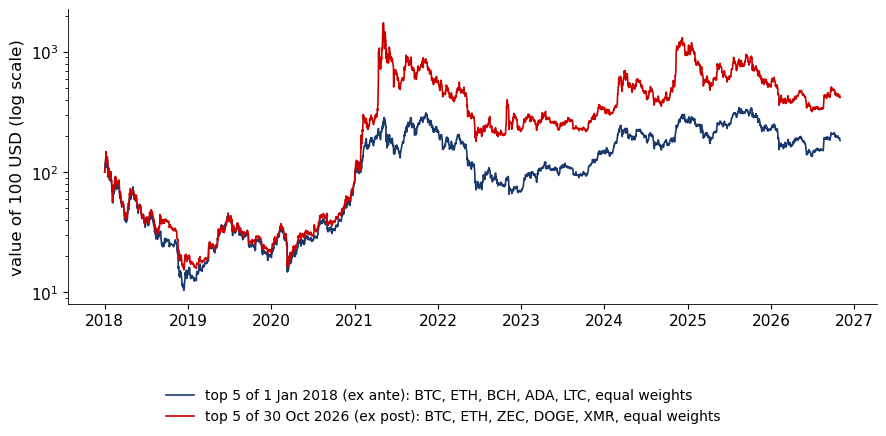

{'ex_ante': ['BTC', 'ETH', 'BCH', 'ADA', 'LTC'], 'ex_post': ['BTC', 'ETH', 'ZEC', 'DOGE', 'XMR'], 'rank_2018': {'BTC': 1, 'ETH': 2, 'DOGE': 10, 'ADA': 4, 'LTC': 5, 'BCH': 3, 'ETC': 8, 'XMR': 7, 'DASH': 6, 'ZEC': 9}, 'rank_now': {'BTC': 1, 'ETH': 2, 'DOGE': 4, 'ADA': 6, 'LTC': 8, 'BCH': 7, 'ETC': 9, 'XMR': 5, 'DASH': 10, 'ZEC': 3}, 'cap_ante_end': np.float64(401.4614272066537), 'cap_post_end': np.float64(491.4022612254618), 'cap_ante_cagr': np.float64(17.054301580529806), 'cap_post_cagr': np.float64(19.766005993912916), 'eq_ante_end': np.float64(183.71476902593577), 'eq_post_end': np.float64(418.09295844104577), 'eq_ante_cagr': np.float64(7.1334599256902775), 'eq_post_cagr': np.float64(17.59384405268303)}


In [7]:
# Survivorship (look-ahead) bias: the top 5 chosen in 2018 against the top 5 of today, both bought on 1 January 2018
t0, t1 = pd.Timestamp('2018-01-01'), pd.Timestamp(END_R)
avail = [c for c in COINS if np.isfinite(MV.loc[t0, c])]
ex_ante = MV.loc[t0, avail].nlargest(5).index.tolist()
ex_post = MV.loc[t1, avail].nlargest(5).index.tolist()


def buy_hold(mem, how='cap'):
    # buy on t0 with market-value (or equal) weights and hold; value 100 on t0
    w = MV.loc[t0, mem] / MV.loc[t0, mem].sum() if how == 'cap' else pd.Series(1 / len(mem), index=mem)
    units = 100 * w / PX.loc[t0, mem]
    return (PX.loc[t0:t1, mem] * units).sum(axis=1, min_count=len(mem))


paths = {f'top 5 of 1 Jan 2018 (ex ante): {", ".join(ex_ante)}': (buy_hold(ex_ante, 'eq'), BLUE),
         f'top 5 of {t1:%d %b %Y} (ex post): {", ".join(ex_post)}': (buy_hold(ex_post, 'eq'), RED)}
fig, ax = plt.subplots(figsize=(9, 4.4))
for lab, (s, c) in paths.items():
    ax.plot(s.index, s, color=c, lw=1.2, label=lab + ', equal weights')
ax.set_yscale('log'); ax.set_ylabel('value of 100 USD (log scale)')
legend_below(fig, ncol=1, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_survivorship')
res = {}
for how in ['cap', 'eq']:
    a, b = buy_hold(ex_ante, how), buy_hold(ex_post, how)
    yrs = (t1 - t0).days / 365.25
    res[how] = dict(ante_end=a.iloc[-1], post_end=b.iloc[-1], ante_cagr=100 * ((a.iloc[-1] / 100) ** (1 / yrs) - 1),
                    post_cagr=100 * ((b.iloc[-1] / 100) ** (1 / yrs) - 1))
RES['surv'] = dict(ex_ante=ex_ante, ex_post=ex_post, rank_2018=MV.loc[t0, avail].rank(ascending=False).astype(int).to_dict(),
                   rank_now=MV.loc[t1, avail].rank(ascending=False).astype(int).to_dict(), **{f'{h}_{k}': v for h, d in res.items() for k, v in d.items()})
print(RES['surv'])

## 3. Constructing CRIX

### 3.1 Laspeyres index and divisor

$$ \mathrm{CRIX}_t = 1000\,\frac{\sum_i P_{it}Q_{i0}}{\sum_i P_{i0}Q_{i0}}, \qquad
   \mathrm{CRIX}_t = \frac{\sum_{i=1}^{k}\mathrm{MV}_{it}}{\mathrm{Divisor}_t}, \qquad
   \mathrm{Divisor}_0 = \frac{\sum_i \mathrm{MV}_{i0}}{1000}. $$

At a rebalancing day $\tau$ the basket changes; the divisor is reset so that the index does not jump:

$$ \mathrm{Divisor}_{\text{new}} = \frac{\sum_i \mathrm{MV}^{\text{new}}_{i\tau}}{\mathrm{CRIX}_\tau}. $$

### 3.2 Number of constituents: the AIC rule and its six-month smoothing

Candidate index $\mathrm{CRIX}(k,\beta)$: the largest coin with weight 1, the next $k-1$ with free weights $\beta$
(Trimborn & Härdle, 2018). Its residual against the total market index (TMI) of the eligible coins is
$\hat\varepsilon_t(k,\beta) = r^{\mathrm{TMI}}_t - r^{\mathrm{CRIX}(k,\beta)}_t$. The density of the residuals of the
one-coin index is estimated with a Gaussian kernel, leave-one-out:

$$ \hat f_{-t}(x) = \frac{1}{(n-1)h}\sum_{s\ne t}\varphi\Big(\frac{x-\hat\varepsilon_s(1,1)}{h}\Big), \qquad
   h = 0.9\,\min(\hat\sigma, \widehat{\mathrm{IQR}}/1.349)\,n^{-1/5}, $$

$$ \mathrm{AIC}(k) = -2\sum_{t=1}^{n}\ln\hat f\big(\hat\varepsilon_t(k,\hat\beta)\big) + 2(k-1). $$

ECRIX rule: stop at the first $k$ where the AIC rises; EFCRIX: global minimum. Smoothed rule: pool the AIC curves of the last six month-ends, fit polynomials in $k$ (degree chosen by AIC) and take the
minimum of the fitted polynomial.

The next cell runs the replica: 35 quarterly reselections (31 March 2018 – 30 September 2026) with the liquidity rule
and the AIC rule on the last 90 days, monthly rebalancing with the new supplies, a divisor, and three benchmarks
(TMI, Bitcoin alone, weights capped below 50%).

In [8]:
# A CRIX-style replica on the ten coins: quarterly reselection (liquidity rule + AIC rule), monthly rebalancing, divisor
qends = [d for d in pd.date_range('2018-03-31', END_R, freq='QE')]
sel = []
for qe in qends:
    elig, adtv, thr = eligible(qe)
    days = pd.date_range(qe - pd.Timedelta(days=89), qe)
    aic, n_, h_ = aic_curve(days, elig)
    order = MV.loc[qe, elig].sort_values(ascending=False).index.tolist()
    sel.append(dict(q=qe, elig=elig, n_elig=len(elig), excluded=[c for c in COINS if c not in elig], order=order, aic=aic,
                    k_ecrix=first_rise(aic), k_efcrix=int(aic.idxmin()), n=n_, h=h_, adtv_thr=thr / 1e6))
# smoothed choice: AIC curves at the six month-ends up to the quarter end, each on its own 90-day window, pooled
for s_ in sel:
    curves = []
    for me in [m for m in month_ends(s_['q'] - pd.Timedelta(days=170), s_['q'])]:
        elig_m, _, _ = eligible(me)
        if set(elig_m) != set(s_['elig']):
            elig_m = [c for c in s_['elig'] if c in elig_m] or s_['elig']
        c_, _, _ = aic_curve(pd.date_range(me - pd.Timedelta(days=89), me), elig_m)
        curves.append(c_)
    s_['k_ctdc'], s_['ctdc_deg'], s_['ctdc_fit'] = smooth_choice(curves)
    s_['ctdc_curves'] = curves

# schedule: members chosen at each quarter end (top k by market value), quantities updated at every month end
def schedule_for(rule):
    sch = []
    for j, s_ in enumerate(sel):
        nxt = sel[j + 1]['q'] if j + 1 < len(sel) else pd.Timestamp(END_R)
        mem = s_['order'][:s_[rule]]
        for me in [s_['q']] + [m for m in month_ends(s_['q'] + pd.Timedelta(days=1), nxt) if m < nxt]:
            sch.append((me, mem))
    return sch


sch = schedule_for('k_ecrix')
rep, div, wts = laspeyres(sch)
rep_cap, div_cap, wts_cap = laspeyres(sch, cap=0.4999)
sch_tmi = []
for j, s_ in enumerate(sel):
    nxt = sel[j + 1]['q'] if j + 1 < len(sel) else pd.Timestamp(END_R)
    for me in [s_['q']] + [m for m in month_ends(s_['q'] + pd.Timedelta(days=1), nxt) if m < nxt]:
        sch_tmi.append((me, s_['elig']))
tmi, div_tmi, w_tmi = laspeyres(sch_tmi)
btc1, _, _ = laspeyres([(me, ['BTC']) for me, _ in sch])
ks = pd.Series({s_['q']: s_['k_ecrix'] for s_ in sel})
RES['rule'] = dict(n_q=len(sel), first=f"{sel[0]['q']:%Y-%m-%d}", last=f"{sel[-1]['q']:%Y-%m-%d}",
                   ecrix_counts={int(k): int(v) for k, v in pd.Series([s_['k_ecrix'] for s_ in sel]).value_counts().sort_index().items()},
                   efcrix_counts={int(k): int(v) for k, v in pd.Series([s_['k_efcrix'] for s_ in sel]).value_counts().sort_index().items()},
                   ctdc_counts={int(k): int(v) for k, v in pd.Series([s_['k_ctdc'] for s_ in sel]).value_counts().sort_index().items()},
                   k_mean=float(ks.mean()), k_last=int(ks.iloc[-1]), k_ctdc_last=int(sel[-1]['k_ctdc']), k_efcrix_last=int(sel[-1]['k_efcrix']),
                   n_elig_mean=float(np.mean([s_['n_elig'] for s_ in sel])),
                   last_aic={int(k): float(v) for k, v in sel[-1]['aic'].items()}, last_order=sel[-1]['order'], last_n=sel[-1]['n'],
                   last_h=sel[-1]['h'], last_excluded=sel[-1]['excluded'], last_thr_musd=sel[-1]['adtv_thr'],
                   ctdc_deg_last=int(sel[-1]['ctdc_deg']),
                   excl_counts={c: int(sum(c in s_['excluded'] for s_ in sel)) for c in COINS})
print(RES['rule'])

{'n_q': 35, 'first': '2018-03-31', 'last': '2026-09-30', 'ecrix_counts': {2: 9, 3: 13, 4: 11, 5: 1, 6: 1}, 'efcrix_counts': {2: 6, 3: 13, 4: 12, 5: 3, 6: 1}, 'ctdc_counts': {3: 30, 4: 1, 6: 1, 7: 3}, 'k_mean': 3.2, 'k_last': 4, 'k_ctdc_last': 3, 'k_efcrix_last': 4, 'n_elig_mean': 7.0, 'last_aic': {1: -662.2349247233126, 2: -946.1926029617616, 3: -953.2681077209313, 4: -953.5729049997915, 5: -952.3282788516667, 6: -950.7158431677607, 7: -948.7715001474353}, 'last_order': ['BTC', 'ETH', 'ZEC', 'DOGE', 'ADA', 'BCH', 'LTC'], 'last_n': 90, 'last_h': np.float64(0.0006854899471917494), 'last_excluded': ['ETC', 'XMR', 'DASH'], 'last_thr_musd': np.float64(130.34138708055556), 'ctdc_deg_last': 5, 'excl_counts': {'BTC': 0, 'ETH': 0, 'DOGE': 12, 'ADA': 9, 'LTC': 0, 'BCH': 0, 'ETC': 5, 'XMR': 33, 'DASH': 24, 'ZEC': 22}}


### 3.3 The decision curve of the last reselection

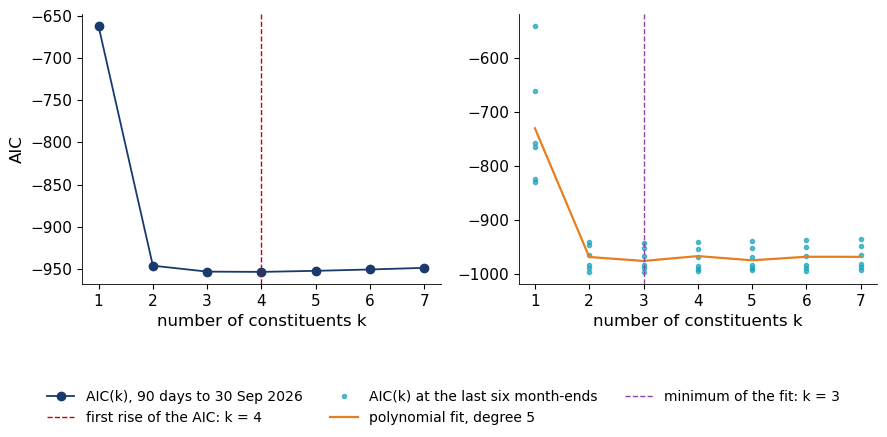

In [9]:
# The decision curve: AIC(k) of the last quarterly reselection, and the smoothed polynomial over six month-ends
s_ = sel[-1]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
a_ = s_['aic']
ax[0].plot(a_.index, a_.values, 'o-', color=BLUE, label=f"AIC(k), 90 days to {s_['q']:%d %b %Y}")
ax[0].axvline(s_['k_ecrix'], color=RED, ls='--', lw=1, label=f"first rise of the AIC: k = {s_['k_ecrix']}")
ax[0].set_xlabel('number of constituents k'); ax[0].set_ylabel('AIC'); ax[0].set_xticks(a_.index)
for j, c_ in enumerate(s_['ctdc_curves']):
    ax[1].plot(c_.index, c_.values, 'o', ms=3, color=TEAL, alpha=0.7, label='AIC(k) at the last six month-ends' if j == 0 else None)
ax[1].plot(s_['ctdc_fit'].index, s_['ctdc_fit'].values, '-', color=ORANGE, lw=1.6, label=f"polynomial fit, degree {s_['ctdc_deg']}")
ax[1].axvline(s_['k_ctdc'], color=PURPLE, ls='--', lw=1, label=f"minimum of the fit: k = {s_['k_ctdc']}")
ax[1].set_xlabel('number of constituents k'); ax[1].set_xticks(a_.index)
legend_below(fig, ncol=3, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_aic_curve')

In [10]:
print(pd.Series(RES['rule']['last_aic']).round(1).to_string())
print('ECRIX choice:', RES['rule']['k_last'], '| EFCRIX:', RES['rule']['k_efcrix_last'], '| smoothed:', RES['rule']['k_ctdc_last'])

1   -662.2
2   -946.2
3   -953.3
4   -953.6
5   -952.3
6   -950.7
7   -948.8
ECRIX choice: 4 | EFCRIX: 4 | smoothed: 3


### 3.4 The number of constituents, quarter by quarter

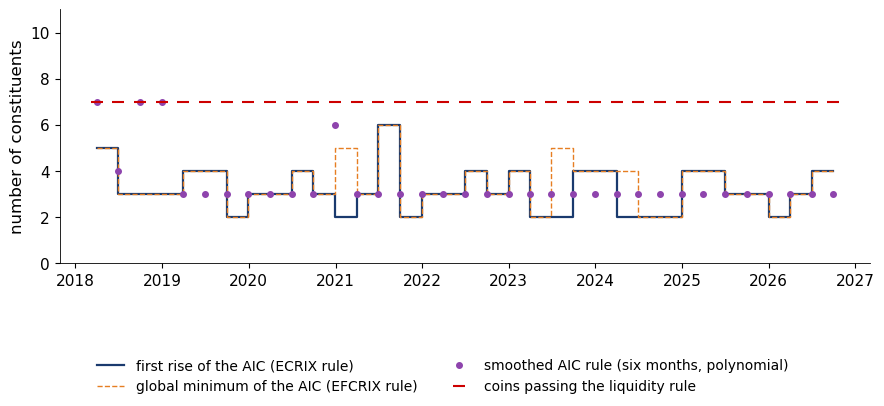

In [11]:
# Number of constituents chosen at each quarterly reselection, three versions of the rule
fig, ax = plt.subplots(figsize=(9, 4.1))
qd = [s_['q'] for s_ in sel]
ax.step(qd, [s_['k_ecrix'] for s_ in sel], where='post', color=BLUE, lw=1.6, label='first rise of the AIC (ECRIX rule)')
ax.step(qd, [s_['k_efcrix'] for s_ in sel], where='post', color=ORANGE, lw=1.0, ls='--', label='global minimum of the AIC (EFCRIX rule)')
ax.plot(qd, [s_['k_ctdc'] for s_ in sel], 'o', color=PURPLE, ms=4, label='smoothed AIC rule (six months, polynomial)')
ax.plot(qd, [s_['n_elig'] for s_ in sel], '_', color=RED, ms=9, mew=1.5, label='coins passing the liquidity rule')
ax.set_ylabel('number of constituents'); ax.set_ylim(0, 11)
legend_below(fig, ncol=2, bottom=0.24)
fix_years(fig); save_fig(fig, 'ba_l3_k_choice')

### 3.5 Worked example: the divisor at the last rebalancing (30 September 2026)

          price    supply_m     mv_bn  weight  price_end
BTC   83553.852      20.092  1678.736  82.074  77198.210
ETH    2683.679     122.090   327.651  16.019   2241.054
ZEC    1436.397      16.895    24.268   1.186   1268.637
DOGE      0.094  156136.493    14.751   0.721      0.076
{'tau': '2026-09-30', 'prev_tau': '2026-08-31', 'I_tau': 9521.153216518393, 'D_new': 214827519.29853904, 'D_prev': 214670934.2901164, 'mv_sum': 2045.405726365952, 'I_end': 8648.48806616303, 'end': '2026-10-30', 'ret_end': -9.165540460386268, 'table': {'BTC': {'price': 83553.8516, 'supply_m': 20.0917, 'mv_bn': 1678.7361, 'weight': 82.0735, 'price_end': 77198.2099}, 'ETH': {'price': 2683.6794, 'supply_m': 122.0902, 'mv_bn': 327.6511, 'weight': 16.0189, 'price_end': 2241.0543}, 'ZEC': {'price': 1436.3969, 'supply_m': 16.895, 'mv_bn': 24.268, 'weight': 1.1865, 'price_end': 1268.637}, 'DOGE': {'price': 0.0945, 'supply_m': 156136.4929, 'mv_bn': 14.7505, 'weight': 0.7212, 'price_end': 0.0759}}, 'n_changes': 102}


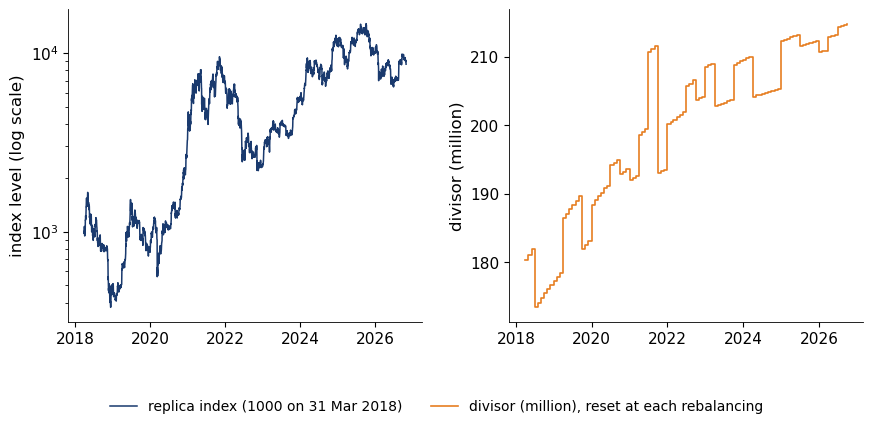

In [12]:
# Worked example of the divisor: the last monthly rebalancing of the replica (numbers from the data)
tau, mem = sch[-1]
prev_tau = sch[-2][0]
I_tau = float(rep.loc[tau])
mvs = MV.loc[tau, mem]
ex = pd.DataFrame({'price': PX.loc[tau, mem], 'supply_m': SUP.loc[tau, mem] / 1e6, 'mv_bn': mvs, 'weight': 100 * mvs / mvs.sum(),
                   'price_end': PX.loc[END_R, mem]})
D_new = float(div.loc[tau])
I_end = float(rep.loc[END_R])
RES['divisor'] = dict(tau=f'{tau:%Y-%m-%d}', prev_tau=f'{prev_tau:%Y-%m-%d}', I_tau=I_tau, D_new=D_new, D_prev=float(div.loc[prev_tau]),
                      mv_sum=float(mvs.sum()), I_end=I_end, end=END_R,
                      ret_end=100 * (I_end / I_tau - 1), table=ex.round(4).to_dict(orient='index'),
                      n_changes=int((div.diff().fillna(0) != 0).sum()))
print(ex.round(3)); print(RES['divisor'])
fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
ax[0].plot(rep.index, rep, color=BLUE, lw=1.1, label='replica index (1000 on 31 Mar 2018)')
ax[0].set_yscale('log'); ax[0].set_ylabel('index level (log scale)')
ax[1].step(div.index, div / 1e6, where='post', color=ORANGE, lw=1.2, label='divisor (million), reset at each rebalancing')
ax[1].set_ylabel('divisor (million)')
legend_below(fig, ncol=2, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_divisor')

### 3.6 Capped weights

A capped market-value index: $\mathrm{CRIX}(k)_t = \sum_i \mathrm{MV}_{it}\mathrm{AW}_{it}/\mathrm{Divisor}$ with
$\mathrm{AW}_{it} = \mathrm{CW}_{it}/W_{it}$ and $W_{it} = \mathrm{MV}_{it}/\sum_j\mathrm{MV}_{jt}$; the capped weight
$\mathrm{CW}_{it}$ keeps every coin below an influence of 50%. Capping: set the weight above the cap to the cap, share
the excess among the others in proportion to their weights, repeat.

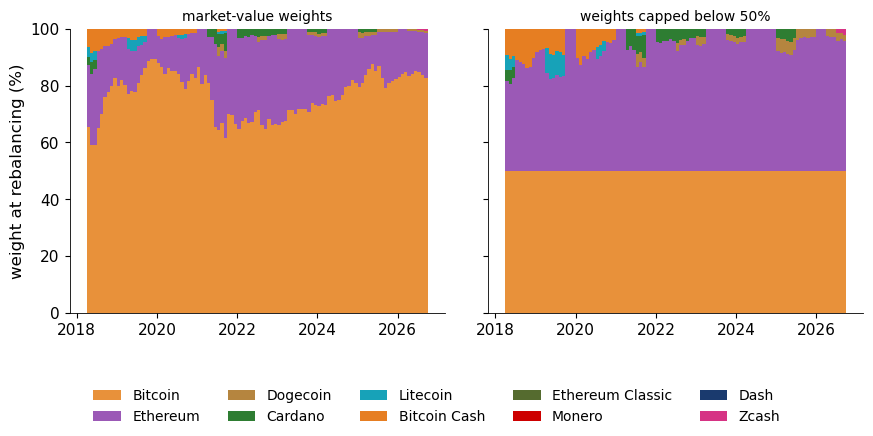

{'btc_mean': np.float64(76.85669882323691), 'btc_min': 59.122378920725126, 'btc_max': 89.26611927330976, 'btc_last': np.float64(82.07350354857749), 'eth_last': np.float64(16.018879401565496), 'cap_eth_last': np.float64(44.68827252682279), 'cap_btc_last': np.float64(49.99), 'last': {'BTC': 82.07350354857749, 'ETH': 16.018879401565496, 'DOGE': 0.7211551501933322, 'ZEC': 1.186461899663675}, 'last_cap': {'BTC': 49.99, 'ETH': 44.68827252682279, 'DOGE': 2.011824739926062, 'ZEC': 3.3099027332511506}, 'share_capped': np.float64(100.0)}


In [13]:
# Weights of the replica at each monthly rebalancing: market-value weights against weights capped below 50%
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4), sharey=True)
for a_, w_, t_ in [(ax[0], wts, 'market-value weights'), (ax[1], wts_cap, 'weights capped below 50%')]:
    a_.stackplot(w_.index, [100 * w_[c] for c in COINS], colors=[CCOL[c] for c in COINS], labels=[CNAME[c] for c in COINS], lw=0, step='post')
    a_.set_title(t_, fontsize=10); a_.set_ylim(0, 100)
ax[0].set_ylabel('weight at rebalancing (%)')
h_, l_ = ax[0].get_legend_handles_labels()
fig.legend(h_, l_, loc='lower center', ncol=5, frameon=False); fig.tight_layout(rect=(0, 0.18, 1, 1))
fix_years(fig); save_fig(fig, 'ba_l3_replica_weights')
RES['weights'] = dict(btc_mean=100 * wts['BTC'].mean(), btc_min=100 * wts['BTC'].min(), btc_max=100 * wts['BTC'].max(),
                      btc_last=100 * wts['BTC'].iloc[-1], eth_last=100 * wts['ETH'].iloc[-1],
                      cap_eth_last=100 * wts_cap['ETH'].iloc[-1], cap_btc_last=100 * wts_cap['BTC'].iloc[-1],
                      last=dict((c, 100 * v) for c, v in wts.iloc[-1].items() if v > 0),
                      last_cap=dict((c, 100 * v) for c, v in wts_cap.iloc[-1].items() if v > 0),
                      share_capped=100 * (wts['BTC'] > 0.4999).mean())
print(RES['weights'])

## 4. The replica against the real CRIX

Tracking error and tracking difference of a portfolio $P$ against a benchmark $B$, daily log returns, $A$ returns a year:

$$ \mathrm{TE} = \sqrt{A}\,\mathrm{sd}(r^P_t - r^B_t), \qquad \mathrm{TD} = \frac{A}{n}\sum_{t=1}^{n}(r^P_t - r^B_t). $$

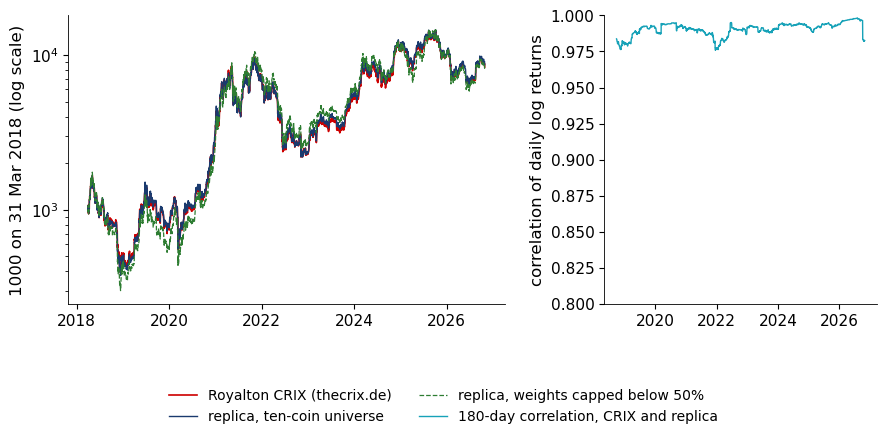

{'start': '2018-03-31', 'end': '2026-10-30', 'n': 3105, 'rep_corr': 0.98965479892351, 'rep_te': 9.308752573689226, 'rep_beta': 0.9960943713990614, 'rep_cap_corr': 0.9791554250427249, 'rep_cap_te': 14.461479387721587, 'rep_cap_beta': 0.9141340771441484, 'tmi_corr': 0.9902024172948448, 'tmi_te': 9.072847542945645, 'tmi_beta': 0.9917127349933867, 'btc1_corr': 0.9709864500393972, 'btc1_te': 15.561289553468907, 'btc1_beta': 1.0204200685023999, 'rep_vs_tmi_corr': 0.9994564140847789, 'rep_vs_tmi_te': 2.154003968382528, 'crix_end': 8380.002817071454, 'rep_end': 8648.48806616303, 'rep_cap_end': 8153.288919379652, 'rc_min': 0.9758337396126836, 'rc_min_date': '2021-12-18', 'rep_stats': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'last': 8648.48806616303, 'cagr': np.float64(28.57610240916937), 'vol': 64.29590317176448, 'n': 3135, 'mdd': -77.29939303930826, 'mdd_peak': '2018-05-05', 'mdd_trough': '2018-12-15'}, 'crix_stats': {'start': '2018-03-31', 'end

In [14]:
# The replica against the real CRIX (official history from 16 March 2018), daily log returns on common days
crix = index_series('crix')
start = sch[0][0]
cmp_ = pd.DataFrame({'crix': crix, 'rep': rep, 'rep_cap': rep_cap, 'tmi': tmi, 'btc1': btc1}).loc[start:END_R]
r_ = cmp_.apply(logret).dropna()
te = lambda a, b: float((r_[a] - r_[b]).std() * np.sqrt(365))
stats_ = {}
for k_ in ['rep', 'rep_cap', 'tmi', 'btc1']:
    stats_[k_] = dict(corr=float(r_['crix'].corr(r_[k_])), te=te('crix', k_), beta=float(np.polyfit(r_[k_], r_['crix'], 1)[0]))
stats_['rep_vs_tmi'] = dict(corr=float(r_['rep'].corr(r_['tmi'])), te=te('rep', 'tmi'))
norm = cmp_.div(cmp_.iloc[0]) * 1000
rc = r_['crix'].rolling(180).corr(r_['rep'])
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(norm.index, norm['crix'], color=RED, lw=1.2, label='Royalton CRIX (thecrix.de)')
ax[0].plot(norm.index, norm['rep'], color=BLUE, lw=1.0, label='replica, ten-coin universe')
ax[0].plot(norm.index, norm['rep_cap'], color=GREEN, lw=0.9, ls='--', label='replica, weights capped below 50%')
ax[0].set_yscale('log'); ax[0].set_ylabel(f'1000 on {start:%d %b %Y} (log scale)')
ax[1].plot(rc.index, rc, color=TEAL, lw=1.0, label='180-day correlation, CRIX and replica')
ax[1].set_ylim(0.8, 1.0); ax[1].set_ylabel('correlation of daily log returns')
ax[1].xaxis.set_major_locator(matplotlib.dates.YearLocator(2)); ax[1].xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%Y'))
legend_below(fig, ncol=2, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_replica_vs_crix')
RES['replica'] = dict(start=f'{start:%Y-%m-%d}', end=END_R, n=len(r_), **{f'{k}_{m}': v for k, d in stats_.items() for m, v in d.items()},
                      crix_end=float(norm['crix'].dropna().iloc[-1]), rep_end=float(norm['rep'].iloc[-1]), rep_cap_end=float(norm['rep_cap'].iloc[-1]),
                      rc_min=float(rc.min()), rc_min_date=f'{rc.idxmin():%Y-%m-%d}',
                      rep_stats=ann_stats(rep), crix_stats=ann_stats(crix.loc[start:END_R]))
print(RES['replica'])

## 5. The real CRIX, 2017–2026

Statistics start on 16 March 2018, the start of the official history; before that date the series comes from a
different data source and moves one day ahead of the EODHD Bitcoin close. CAGR $= (I_T/I_0)^{1/T} - 1$; drawdown
$D_t = I_t/\max_{s\le t} I_s - 1$.

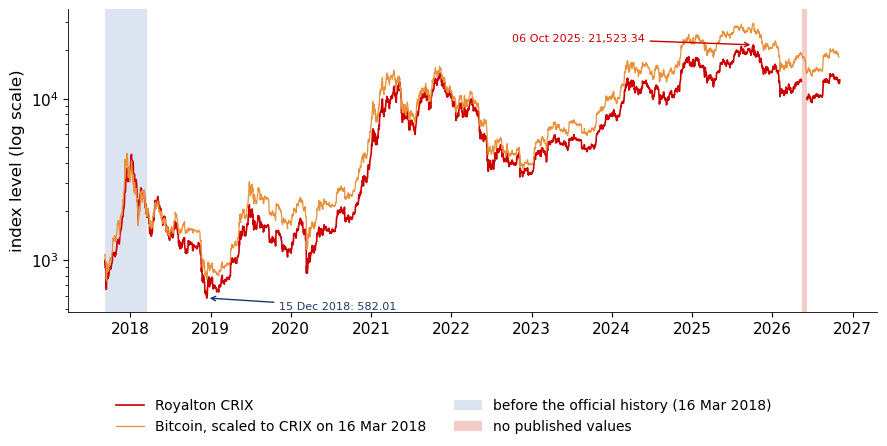

{'full': {'start': '2017-09-06', 'end': '2026-11-06', 'years': 9.166324435318275, 'first': 996.95, 'last': 12250.34, 'cagr': np.float64(31.47895085216703), 'vol': 68.61437999346741, 'n': 3316, 'mdd': -87.09592309124932, 'mdd_peak': '2018-01-05', 'mdd_trough': '2018-12-15'}, 'official': {'start': '2018-03-16', 'end': '2026-11-06', 'years': 8.643394934976044, 'first': 1960.12, 'last': 12250.34, 'cagr': np.float64(23.61690902610345), 'vol': 64.93562476988464, 'n': 3125, 'mdd': -77.43561915453128, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-09'}, 'official_to_oct': {'start': '2018-03-16', 'end': '2026-10-31', 'years': 8.626967830253252, 'first': 1960.12, 'last': 12512.61, 'cagr': np.float64(23.970858042299415), 'vol': 64.95861882524186, 'n': 3121, 'mdd': -77.43561915453128, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-09'}, 'btc_official': {'start': '2018-03-16', 'end': '2026-10-31', 'years': 8.626967830253252, 'first': 8338.349609375, 'last': 77214.2890625, 'cagr': np.float64(29.

In [15]:
# The real CRIX, 6 September 2017 - 6 November 2026, against Bitcoin (EODHD close), and its main episodes
crix = index_series('crix')
btc = daily('BTC-USD.CC').reindex(crix.index)
pk = crix.idxmax()
cs = ann_stats(crix)
cs_off = ann_stats(crix.loc[OFFICIAL:])
bs_off = ann_stats(btc.loc[OFFICIAL:'2026-10-31'])
cs_off_c = ann_stats(crix.loc[OFFICIAL:'2026-10-31'])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(crix.index, crix, color=RED, lw=1.2, label='Royalton CRIX')
ax.plot(btc.index, btc / btc.loc[OFFICIAL] * crix.loc[OFFICIAL], color=BTC, lw=0.9, label=f'Bitcoin, scaled to CRIX on {pd.Timestamp(OFFICIAL):%d %b %Y}')
ax.axvspan(crix.index[0], pd.Timestamp(OFFICIAL), color='#C5D2E8', alpha=0.6, lw=0, label='before the official history (16 Mar 2018)')
ax.axvspan(pd.Timestamp('2026-05-14'), pd.Timestamp('2026-06-07'), color='#F4C7C3', alpha=0.9, lw=0, label='no published values')
ax.annotate(f'{pk:%d %b %Y}: {crix.max():,.2f}', xy=(pk, crix.max()), xytext=(pk - pd.Timedelta(days=1100), crix.max() * 1.05), fontsize=8,
            color=RED, arrowprops=dict(arrowstyle='->', color=RED))
tr = crix.loc[:'2019'].idxmin()
ax.annotate(f'{tr:%d %b %Y}: {crix.loc[tr]:,.2f}', xy=(tr, crix.loc[tr]), xytext=(tr + pd.Timedelta(days=330), crix.loc[tr] * 0.85), fontsize=8,
            color=BLUE, arrowprops=dict(arrowstyle='->', color=BLUE))
ax.set_yscale('log'); ax.set_ylabel('index level (log scale)')
legend_below(fig, ncol=2, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_crix_path')
r_c = logret(crix).loc[OFFICIAL:'2026-10-31']; r_b = logret(btc).loc[OFFICIAL:'2026-10-31']
j_ = pd.concat([r_c, r_b], axis=1, keys=['c', 'b']).dropna()
ols = sm.OLS(j_['c'], sm.add_constant(j_['b'])).fit()
gaps = crix.isna()
RES['crix'] = dict(full=cs, official=cs_off, official_to_oct=cs_off_c, btc_official=bs_off, peak=float(crix.max()), peak_date=f'{pk:%Y-%m-%d}',
                   n_obs=int(crix.notna().sum()), n_missing=int(gaps.sum()), gap_from='2026-05-14', gap_to='2026-06-07',
                   corr_btc=float(j_['c'].corr(j_['b'])), beta_btc=float(ols.params['b']), beta_se=float(ols.bse['b']), r2_btc=float(ols.rsquared),
                   n_joint=len(j_), vol_c=float(j_['c'].std() * np.sqrt(365)), vol_b=float(j_['b'].std() * np.sqrt(365)),
                   te_btc=float((j_['c'] - j_['b']).std() * np.sqrt(365)),
                   latest=float(crix.dropna().iloc[-1]), latest_date=f'{crix.dropna().index[-1]:%Y-%m-%d}',
                   from_peak=100 * float(crix.dropna().iloc[-1] / crix.max() - 1),
                   worst_day=float(r_c.min()), worst_date=f'{r_c.idxmin():%Y-%m-%d}', best_day=float(r_c.max()), best_date=f'{r_c.idxmax():%Y-%m-%d}',
                   skew=float(stats.skew(r_c.dropna())), exkurt=float(stats.kurtosis(r_c.dropna())))
print(RES['crix'])

### 5.1 Drawdowns, episodes and shocks

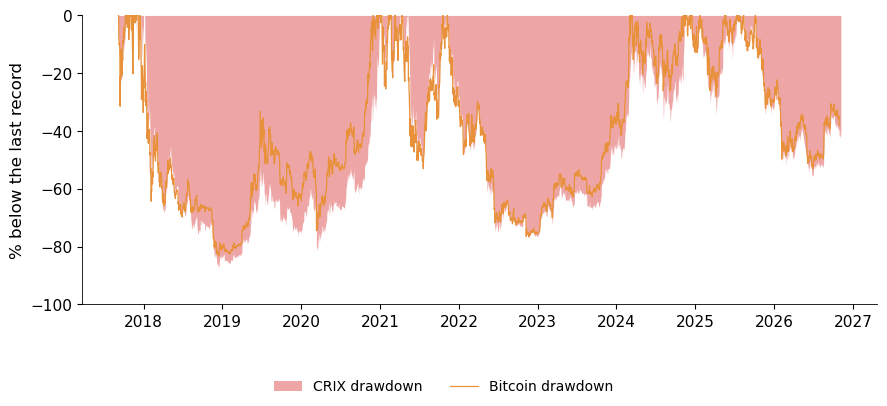

{'episodes': [{'peak': '2018-01-05', 'peak_v': 4510.28, 'trough': '2018-12-15', 'trough_v': 582.01, 'depth': -87.09592309124932, 'recovered': '2020-12-31', 'days': 1091}, {'peak': '2021-05-09', 'peak_v': 12644.7, 'trough': '2021-07-20', 'trough_v': 5994.23, 'depth': -52.5949211922782, 'recovered': '2021-10-19', 'days': 163}, {'peak': '2021-11-08', 'peak_v': 14484.51, 'trough': '2022-11-09', 'trough_v': 3268.34, 'depth': -77.43561915453128, 'recovered': '2024-11-11', 'days': 1099}, {'peak': '2025-10-06', 'peak_v': 21523.34, 'trough': '2026-06-30', 'trough_v': 9439.22, 'depth': -56.144260138064084, 'recovered': None, 'days': None}], 'shocks': {'COVID-19': {'crix': -44.950728454418595, 'btc': -40.63909377366025}, 'Terra/Luna': {'crix': -31.00732144927982, 'btc': -23.042777077099846}, 'FTX': {'crix': -33.821492025970116, 'btc': -29.86893152894543}}, 'mdd_btc': -83.3990092003427, 'mdd_btc_date': '2018-12-15', 'share_below50_crix': 48.84071062932851, 'share_below50_btc': 39.90427759497457, '

In [16]:
# Drawdowns of CRIX and Bitcoin, and the episodes deeper than 50%
dd_c = crix.dropna() / crix.dropna().cummax() - 1
bb = btc.loc[crix.index[0]:'2026-10-31'].dropna()
dd_b = bb / bb.cummax() - 1
fig, ax = plt.subplots(figsize=(9, 4.1))
ax.fill_between(dd_c.index, 100 * dd_c, 0, color=RED, alpha=0.35, lw=0, label='CRIX drawdown')
ax.plot(dd_b.index, 100 * dd_b, color=BTC, lw=0.9, label='Bitcoin drawdown')
ax.set_ylabel('% below the last record'); ax.set_ylim(-100, 0)
legend_below(fig, ncol=2, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_crix_drawdown')


def episodes(s, depth=0.5):
    # peaks, troughs and recoveries of the falls deeper than `depth`
    s = s.dropna(); out = []; peak_v, peak_d, i = s.iloc[0], s.index[0], 0
    trough_v, trough_d, in_dd = None, None, False
    for d, v in s.items():
        if v >= peak_v:
            if in_dd and trough_v / peak_v - 1 <= -depth:
                out.append(dict(peak=f'{peak_d:%Y-%m-%d}', peak_v=float(peak_v), trough=f'{trough_d:%Y-%m-%d}', trough_v=float(trough_v),
                                depth=100 * float(trough_v / peak_v - 1), recovered=f'{d:%Y-%m-%d}', days=int((d - peak_d).days)))
            peak_v, peak_d, in_dd, trough_v = v, d, False, None
        else:
            in_dd = True
            if trough_v is None or v < trough_v:
                trough_v, trough_d = v, d
    if in_dd:
        out.append(dict(peak=f'{peak_d:%Y-%m-%d}', peak_v=float(peak_v), trough=f'{trough_d:%Y-%m-%d}', trough_v=float(trough_v),
                        depth=100 * float(trough_v / peak_v - 1), recovered=None, days=None))
    return out


ep = episodes(crix)
# crypto-specific and global shocks (same windows as Lecture 2): cumulative log returns, %
win = {'COVID-19': ('2020-02-19', '2020-03-23'), 'Terra/Luna': ('2022-05-05', '2022-05-12'), 'FTX': ('2022-11-05', '2022-11-21')}
shocks = {k: dict(crix=100 * float(np.log(crix.loc[b] / crix.loc[a])), btc=100 * float(np.log(btc.loc[b] / btc.loc[a]))) for k, (a, b) in win.items()}
yr = pd.DataFrame({'CRIX': crix.loc[OFFICIAL:'2026-10-31'], 'Bitcoin': btc.loc[OFFICIAL:'2026-10-31']}).dropna()
ye = yr.groupby(yr.index.year).last()
yret = 100 * (ye / ye.shift(1) - 1)
yret.loc[2018] = 100 * (ye.loc[2018] / yr.iloc[0] - 1)
RES['dd'] = dict(episodes=ep, shocks=shocks, mdd_btc=100 * float(dd_b.min()), mdd_btc_date=f'{dd_b.idxmin():%Y-%m-%d}',
                 share_below50_crix=100 * float((dd_c < -0.5).mean()), share_below50_btc=100 * float((dd_b < -0.5).mean()),
                 years={int(y): dict(crix=float(v['CRIX']), btc=float(v['Bitcoin'])) for y, v in yret.sort_index().iterrows()})
print(RES['dd'])

### 5.2 Calendar-year returns

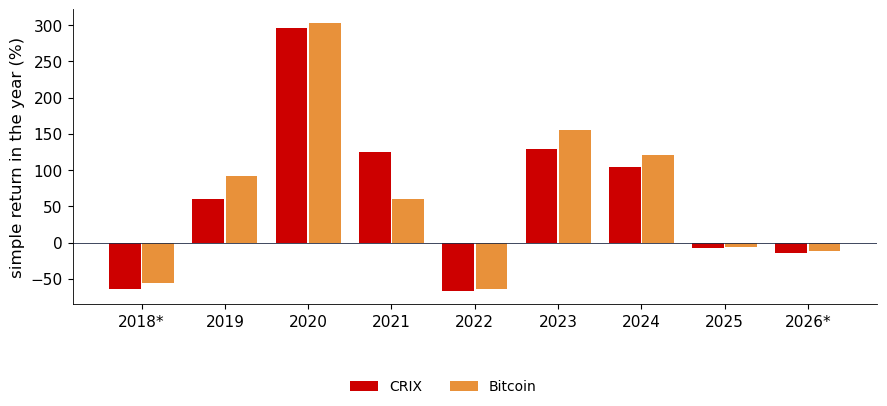

In [17]:
# Calendar-year returns of CRIX and Bitcoin (2018 from 16 March, 2026 to 31 October)
yy = yret.sort_index()
x_ = np.arange(len(yy))
fig, ax = plt.subplots(figsize=(9, 4.1))
ax.bar(x_ - 0.2, yy['CRIX'], 0.38, color=RED, label='CRIX')
ax.bar(x_ + 0.2, yy['Bitcoin'], 0.38, color=BTC, label='Bitcoin')
ax.axhline(0, color=NAVY, lw=0.6)
ax.set_xticks(x_); ax.set_xticklabels([('2018*' if y == 2018 else '2026*' if y == 2026 else str(y)) for y in yy.index])
ax.set_ylabel('simple return in the year (%)')
legend_below(fig, ncol=2, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_crix_years')
RES['years_better_crix'] = int((yy['CRIX'] > yy['Bitcoin']).sum())

## 6. VCRIX: a volatility index

Realised volatility over the last $w$ days, annualised ($r_t$ in %):
$\mathrm{RV}^{(w)}_t = \sqrt{\tfrac{365}{w}\sum_{j=0}^{w-1} r_{t-j}^2}$. VCRIX (Kim, Trimborn & Härdle, 2021) is a HAR
forecast of this proxy, normalised to 1000 on its first day. The window from 14 May to 8 July 2026 (data gap of CRIX
and the 30 days after it) is excluded from the statistics.

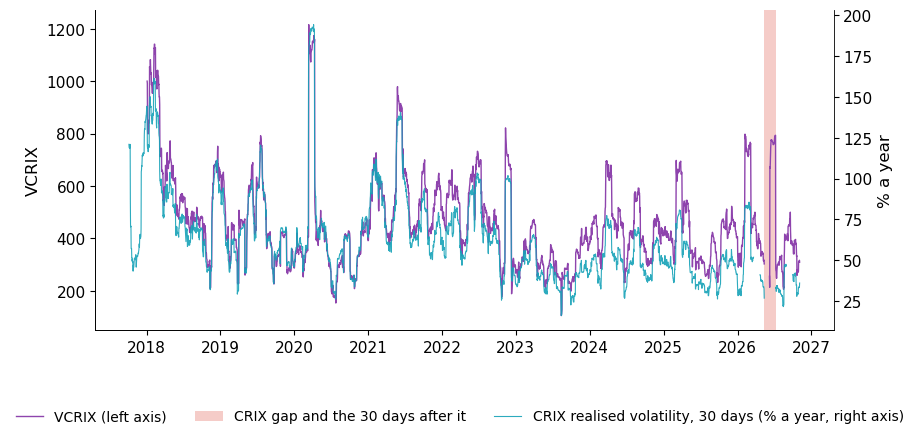

{'first': 1000.0, 'first_date': '2018-01-04', 'mean': 457.70289905362773, 'median': 426.69, 'max': 1215.57, 'max_date': '2020-03-13', 'min': 105.09, 'min_date': '2023-08-14', 'latest': 342.13, 'latest_date': '2026-11-06', 'corr_rv': 0.9302554398040197, 'corr_rv_l1': 0.9432089352098298, 'n': 3020, 'slope_rv': 6.114859570777094, 'const_rv': 74.3775007887071, 'r2_rv': 0.8896430954596599, 'p80': 582.4820000000001, 'p20': 315.31800000000004, 'jump_2020': {'before': 405.66, 'after': 1215.57, 'd30_before': 1159.78, 'd30_after': 542.82}, 'jump_2026': {'before': 213.04, 'after': 673.24, 'out_before': 793.12, 'out_after': 283.93}}


In [18]:
# VCRIX, 4 January 2018 - 6 November 2026, and the realised volatility of CRIX (30 days, annualised)
vcrix = index_series('vcrix')
rc_ = logret(crix)
rv30 = np.sqrt((rc_ ** 2).rolling(30, min_periods=30).mean() * 365)        # % a year, from consecutive-day returns only
art = (vcrix.index >= '2026-05-14') & (vcrix.index <= '2026-07-08')        # data gap and the 30 days after it
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(vcrix.index, vcrix, color=PURPLE, lw=1.0, label='VCRIX (left axis)')
ax.axvspan(pd.Timestamp('2026-05-14'), pd.Timestamp('2026-07-08'), color='#F4C7C3', alpha=0.9, lw=0, label='CRIX gap and the 30 days after it')
ax.set_ylabel('VCRIX')
ax2 = ax.twinx()
ax2.plot(rv30.index, rv30, color=TEAL, lw=0.8, alpha=0.9, label='CRIX realised volatility, 30 days (% a year, right axis)')
ax2.set_ylabel('% a year'); ax2.spines['right'].set_visible(True)
legend_below(fig, ncol=3, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_path')
v_ok = vcrix.copy(); v_ok[art] = np.nan
jj = pd.concat([v_ok, rv30, rv30.shift(1)], axis=1, keys=['v', 'rv', 'rv_l1']).loc[:'2026-05-13'].dropna()
fitv = sm.OLS(jj['v'], sm.add_constant(jj['rv_l1'])).fit()
RES['vcrix'] = dict(first=float(vcrix.dropna().iloc[0]), first_date=f'{vcrix.dropna().index[0]:%Y-%m-%d}', mean=float(v_ok.mean()), median=float(v_ok.median()),
                    max=float(v_ok.max()), max_date=f'{v_ok.idxmax():%Y-%m-%d}', min=float(v_ok.min()), min_date=f'{v_ok.idxmin():%Y-%m-%d}',
                    latest=float(vcrix.dropna().iloc[-1]), latest_date=f'{vcrix.dropna().index[-1]:%Y-%m-%d}',
                    corr_rv=float(jj['v'].corr(jj['rv'])), corr_rv_l1=float(jj['v'].corr(jj['rv_l1'])), n=len(jj),
                    slope_rv=float(fitv.params['rv_l1']), const_rv=float(fitv.params['const']), r2_rv=float(fitv.rsquared),
                    p80=float(v_ok.quantile(0.8)), p20=float(v_ok.quantile(0.2)),
                    jump_2020=dict(before=float(vcrix.loc['2020-03-12']), after=float(vcrix.loc['2020-03-13']),
                                   d30_before=float(vcrix.loc['2020-04-11']), d30_after=float(vcrix.loc['2020-04-12'])),
                    jump_2026=dict(before=float(vcrix.loc['2026-06-09']), after=float(vcrix.loc['2026-06-10']),
                                   out_before=float(vcrix.loc['2026-07-08']), out_after=float(vcrix.loc['2026-07-09'])))
print(RES['vcrix'])

### 6.1 Volatility after falls and rises

Change of $\ln$ VCRIX on day $t$ against the CRIX return on day $t-1$, with separate slopes for falls and rises
(heteroskedasticity- and autocorrelation-consistent standard errors).

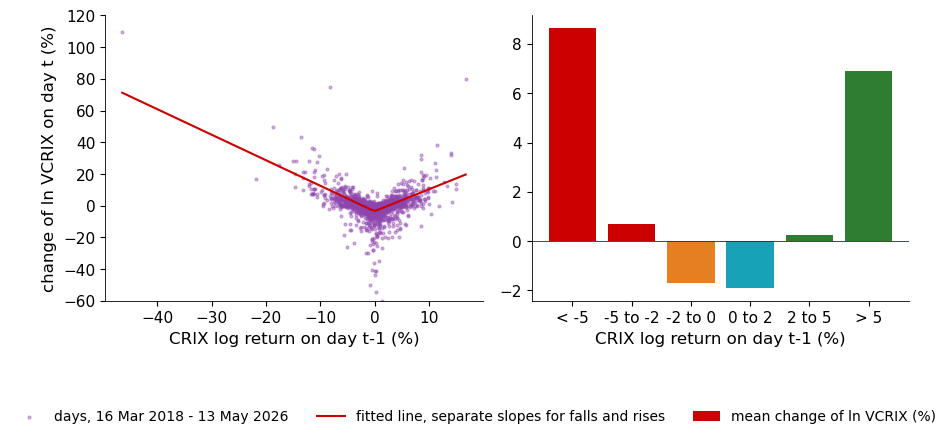

{'n': 2978, 'corr_same': 0.0065370364572868295, 'corr_lag1': -0.13240397149636451, 'b_neg': -1.6078520692740543, 'se_neg': 0.14487555792779336, 'b_pos': 1.3770082081698372, 'se_pos': 0.11602881491565842, 'const': -3.4968336175859185, 'p_equal': 0.10440507929789283, 'r2': 0.32974110406382007, 'bins': {'(-60, -5]': 8.62884887346821, '(-5, -2]': 0.6838903835782205, '(-2, 0]': -1.7016430685384891, '(0, 2]': -1.8928573228243135, '(2, 5]': 0.2677814251503702, '(5, 60]': 6.917200945975502}, 'bin_n': {'(-60, -5]': 174, '(-5, -2]': 403, '(-2, 0]': 826, '(0, 2]': 927, '(2, 5]': 480, '(5, 60]': 168}}


In [19]:
# Volatility and returns: change of log VCRIX on day t against the CRIX return of day t - 1 (VCRIX reacts one day later)
dv = 100 * np.log(v_ok).diff()
L_ = pd.concat([dv, rc_.shift(1), rc_], axis=1, keys=['dv', 'r_l1', 'r']).loc[OFFICIAL:'2026-05-13'].dropna()
cor0, cor1 = float(L_['dv'].corr(L_['r'])), float(L_['dv'].corr(L_['r_l1']))
neg, pos = L_[L_['r_l1'] < 0], L_[L_['r_l1'] >= 0]
X = pd.DataFrame({'r_neg': L_['r_l1'].clip(upper=0), 'r_pos': L_['r_l1'].clip(lower=0)})
fit = sm.OLS(L_['dv'], sm.add_constant(X)).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
big = L_[L_['r_l1'].abs() > 5]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
ax[0].scatter(L_['r_l1'], L_['dv'], s=4, color=PURPLE, alpha=0.4, label='days, 16 Mar 2018 - 13 May 2026')
xx = np.linspace(L_['r_l1'].min(), L_['r_l1'].max(), 100)
ax[0].plot(xx, fit.params['const'] + fit.params['r_neg'] * np.minimum(xx, 0) + fit.params['r_pos'] * np.maximum(xx, 0), color=RED, lw=1.5,
           label='fitted line, separate slopes for falls and rises')
ax[0].set_xlabel('CRIX log return on day t-1 (%)'); ax[0].set_ylabel('change of ln VCRIX on day t (%)')
ax[0].set_ylim(-60, 120)
bins = pd.cut(L_['r_l1'], [-60, -5, -2, 0, 2, 5, 60])
mb = L_.groupby(bins, observed=True)['dv'].mean()
ax[1].bar(range(len(mb)), mb.values, color=[RED, RED, ORANGE, TEAL, GREEN, GREEN], label='mean change of ln VCRIX (%)')
ax[1].set_xticks(range(len(mb))); ax[1].set_xticklabels(['< -5', '-5 to -2', '-2 to 0', '0 to 2', '2 to 5', '> 5'])
ax[1].set_xlabel('CRIX log return on day t-1 (%)'); ax[1].axhline(0, color=NAVY, lw=0.6)
legend_below(fig, ncol=3, bottom=0.16)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_leverage')
RES['lev'] = dict(n=len(L_), corr_same=cor0, corr_lag1=cor1, b_neg=float(fit.params['r_neg']), se_neg=float(fit.bse['r_neg']),
                  b_pos=float(fit.params['r_pos']), se_pos=float(fit.bse['r_pos']), const=float(fit.params['const']),
                  p_equal=float(fit.f_test('r_neg + r_pos = 0').pvalue), r2=float(fit.rsquared),
                  bins={str(k): float(v) for k, v in mb.items()}, bin_n={str(k): int(v) for k, v in L_.groupby(bins, observed=True).size().items()})
print(RES['lev'])

### 6.2 A GARCH(1,1) volatility for CRIX

$$ r_t = \mu + \sigma_t z_t,\quad z_t \sim t_\nu,\qquad \sigma_t^2 = \omega + \alpha(r_{t-1}-\mu)^2 + \beta\sigma_{t-1}^2. $$

Estimated on 16 March 2018 – 13 May 2026 (before the data gap); the half-life of a variance shock is
$\ln 0.5/\ln(\alpha+\beta)$.

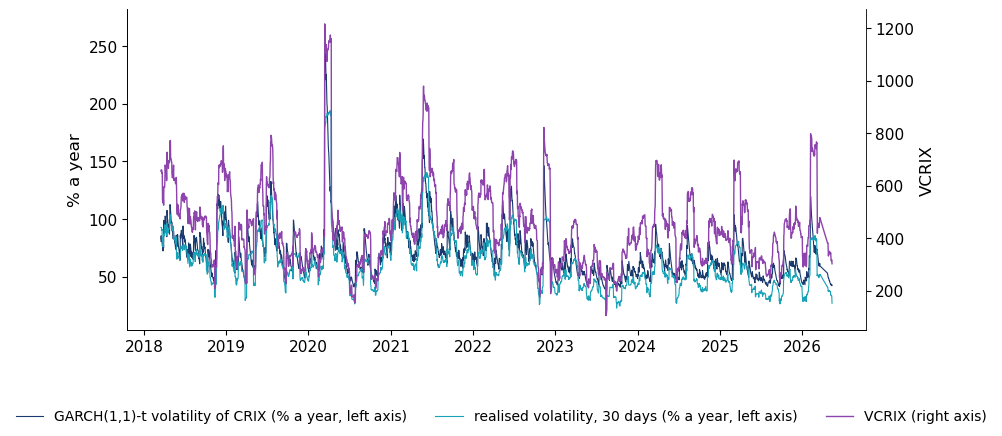

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         crix   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -7456.62
Distribution:      Standardized Student's t   AIC:                           14923.2
Method:                  Maximum Likelihood   BIC:                           14953.2
                                              No. Observations:                 2979
Date:                      Sat, Nov 07 2026   Df Residuals:                     2978
Time:                              19:51:44   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [20]:
# GARCH(1,1) with Student-t errors for CRIX daily log returns (%), 16 March 2018 - 13 May 2026 (before the data gap)
from arch import arch_model
rg = rc_.loc[OFFICIAL:'2026-05-13']
n_skip = int(rg.isna().sum())                                            # the two returns around the missing 22 March 2026
rg = rg.dropna()
am = arch_model(rg, mean='Constant', vol='GARCH', p=1, q=1, dist='t')
gf = am.fit(disp='off')
sig = gf.conditional_volatility * np.sqrt(365)                             # % a year
# one-step forecast for day t+1 made with information up to t, so it is comparable with VCRIX published for day t+1
f1 = np.sqrt(gf.params['omega'] + gf.params['alpha[1]'] * (rg - gf.params['mu']) ** 2 + gf.params['beta[1]'] * gf.conditional_volatility ** 2) * np.sqrt(365)
G = pd.concat([v_ok, sig, f1.shift(1), rv30], axis=1, keys=['v', 'g', 'gf', 'rv']).loc[OFFICIAL:'2026-05-13'].dropna()
pers = gf.params['alpha[1]'] + gf.params['beta[1]']
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(G.index, G['gf'], color=BLUE, lw=0.8, label='GARCH(1,1)-t volatility of CRIX (% a year, left axis)')
ax.plot(G.index, G['rv'], color=TEAL, lw=0.8, label='realised volatility, 30 days (% a year, left axis)')
ax.set_ylabel('% a year')
ax2 = ax.twinx(); ax2.plot(G.index, G['v'], color=PURPLE, lw=1.0, label='VCRIX (right axis)'); ax2.set_ylabel('VCRIX')
ax2.spines['right'].set_visible(True)
legend_below(fig, ncol=3, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_garch')
RES['garch'] = dict(n=len(rg), n_skip=n_skip, mu=float(gf.params['mu']), omega=float(gf.params['omega']), alpha=float(gf.params['alpha[1]']),
                    beta=float(gf.params['beta[1]']), nu=float(gf.params['nu']),
                    se={k: float(v) for k, v in gf.std_err.items()}, pers=float(pers), half_life=float(np.log(0.5) / np.log(pers)),
                    uncond_vol=float(np.sqrt(gf.params['omega'] / (1 - pers)) * np.sqrt(365)), loglik=float(gf.loglikelihood),
                    corr_v_g=float(G['v'].corr(G['gf'])), corr_v_rv=float(G['v'].corr(G['rv'])), corr_g_rv=float(G['gf'].corr(G['rv'])),
                    corr_logv_logg=float(np.log(G['v']).corr(np.log(G['gf']))), n_cmp=len(G),
                    g_mean=float(G['gf'].mean()), rv_mean=float(G['rv'].mean()), g_max=float(G['gf'].max()), g_max_date=f"{G['gf'].idxmax():%Y-%m-%d}")
print(gf.summary()); print(RES['garch'])

### 6.3 Our HAR forecast of next month's volatility

$$ \mathrm{RV}_{t+1:t+30} = c + \beta_d\,\mathrm{RV}^{(1)}_t + \beta_w\,\mathrm{RV}^{(7)}_t + \beta_m\,\mathrm{RV}^{(30)}_t + u_t, $$

estimated by OLS on 2018–2023 (chronological split, no shuffling), tested on 2024 – February 2026 against the naive
forecast ``next month = last month''.

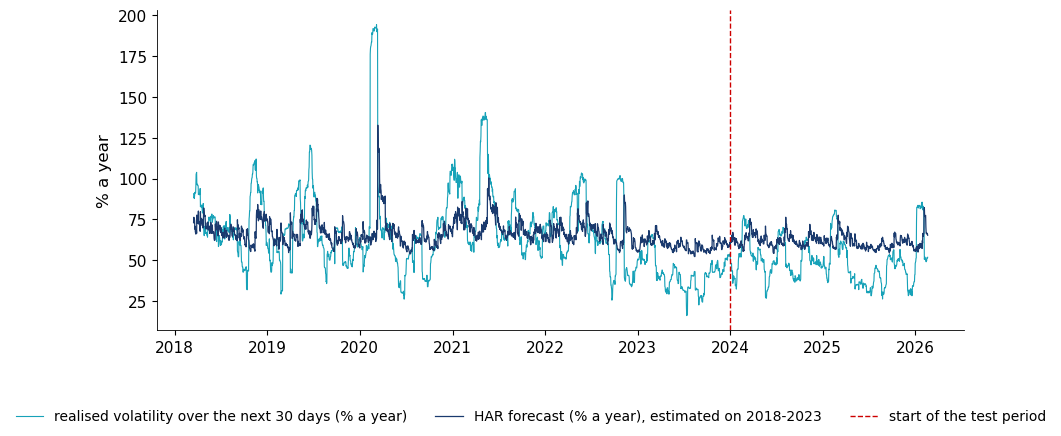

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         48.0241      6.493      7.396      0.000      35.297      60.751
d              0.0212      0.007      2.941      0.003       0.007       0.035
w              0.1121      0.042      2.644      0.008       0.029       0.195
m              0.1526      0.089      1.709      0.087      -0.022       0.328
{'n_train': 2117, 'n_test': 781, 'params': {'const': 48.02413443980273, 'd': 0.021204987771311856, 'w': 0.11209367274538638, 'm': 0.152592574491371}, 'se': {'const': 6.493331764808969, 'd': 0.007209635253063457, 'w': 0.04239363164263818, 'm': 0.08927126985327458}, 'r2_train': 0.08847139150425387, 'r2_oos': 0.26837182656570824, 'r2_oos_naive': 0.24614833947666004, 'corr_har_vcrix': 0.7938355087156749, 'corr_har_vcrix_test': 0.7263815128667661, 'rmse_test': 18.36929856780346, 'rmse_naive': 18.646198813427358}


In [21]:
# Own HAR model (Corsi, 2009) for the next 30 days' realised volatility of CRIX; train to end-2023, test from 2024
a_ = np.abs(rc_) * np.sqrt(365)                                           # daily component, % a year
rv7 = np.sqrt((rc_ ** 2).rolling(7, min_periods=7).mean() * 365)        # weekly component
fut = np.sqrt((rc_ ** 2).rolling(30, min_periods=30).mean().shift(-30) * 365)   # target: realised vol over t+1..t+30
H = pd.concat([fut, a_, rv7, rv30, v_ok], axis=1, keys=['y', 'd', 'w', 'm', 'v']).loc[OFFICIAL:'2026-05-13']
H = H.dropna(subset=['y', 'd', 'w', 'm'])
tr_, te_ = H.loc[:'2023-12-31'], H.loc['2024-01-01':]
har = sm.OLS(tr_['y'], sm.add_constant(tr_[['d', 'w', 'm']])).fit(cov_type='HAC', cov_kwds={'maxlags': 30})
pred = har.predict(sm.add_constant(H[['d', 'w', 'm']]))
oos_r2 = 1 - ((te_['y'] - pred.loc[te_.index]) ** 2).sum() / ((te_['y'] - tr_['y'].mean()) ** 2).sum()
naive_r2 = 1 - ((te_['y'] - te_['m']) ** 2).sum() / ((te_['y'] - tr_['y'].mean()) ** 2).sum()
vv = pd.concat([pred, H['v']], axis=1, keys=['p', 'v']).dropna()
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(H.index, H['y'], color=TEAL, lw=0.8, label='realised volatility over the next 30 days (% a year)')
ax.plot(pred.index, pred, color=BLUE, lw=0.9, label='HAR forecast (% a year), estimated on 2018-2023')
ax.axvline(pd.Timestamp('2024-01-01'), color=RED, ls='--', lw=1, label='start of the test period')
ax.set_ylabel('% a year')
legend_below(fig, ncol=3, bottom=0.14)
fix_years(fig); save_fig(fig, 'ba_l3_vcrix_har')
RES['har'] = dict(n_train=len(tr_), n_test=len(te_), params={k: float(v) for k, v in har.params.items()},
                  se={k: float(v) for k, v in har.bse.items()}, r2_train=float(har.rsquared), r2_oos=float(oos_r2), r2_oos_naive=float(naive_r2),
                  corr_har_vcrix=float(vv['p'].corr(vv['v'])), corr_har_vcrix_test=float(vv.loc['2024':, 'p'].corr(vv.loc['2024':, 'v'])),
                  rmse_test=float(np.sqrt(((te_['y'] - pred.loc[te_.index]) ** 2).mean())),
                  rmse_naive=float(np.sqrt(((te_['y'] - te_['m']) ** 2).mean())))
print(har.summary().tables[1]); print(RES['har'])

## 7. From index to fund: a spot Bitcoin ETF

IBIT (adjusted close, 16:00 New York) against Bitcoin at 16:00 New York (hourly bar 15:00–16:00) and at 24:00 UTC
(daily close). Tracking difference: the trend of $\ln(\mathrm{IBIT}/\mathrm{BTC})$; tracking error with $A = 252$.

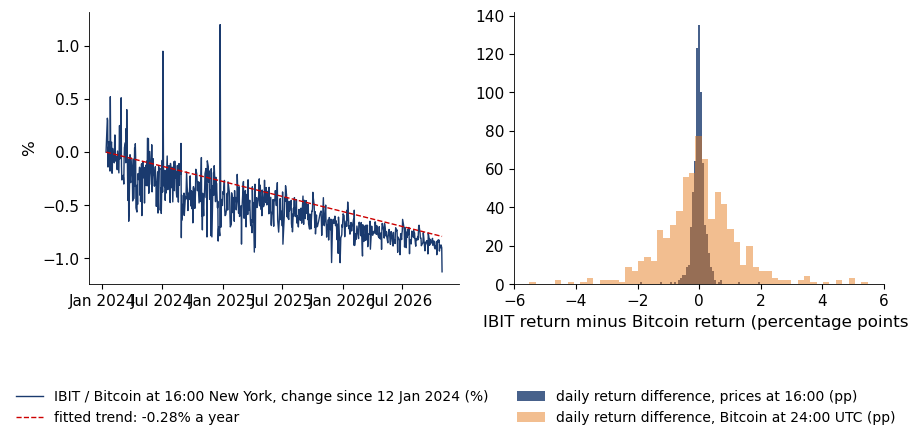

{'start': '2024-01-12', 'end': '2026-10-30', 'n': 697, 'te16': 3.5414305312450454, 'te00': 20.61705356818672, 'td_slope': -0.28496320780554074, 'ratio_change': -1.1274765213104776, 'corr16': 0.9975081748875947, 'corr00': 0.9073934867780629, 'sd_diff16': 0.22308915407347019, 'sd_diff00': 1.2987522978171169, 'ib_ret': 73.6483780536644, 'btc_ret': 75.62854870503195}


In [22]:
# A spot Bitcoin exchange-traded fund (iShares IBIT) against Bitcoin: tracking difference and tracking error
ib = market_file('IBIT.US')['adjusted_close']
ib = ib[(ib > 0) & (ib.index >= '2024-01-12')]
h = pd.read_csv(data_file('hourly', 'BTC-USD.CC_1h.csv'))
h.index = pd.DatetimeIndex(pd.to_datetime(h['timestamp'], unit='s', utc=True)).tz_convert('America/New_York')
b16 = h['close'][h.index.hour == 15]                                           # the bar 15:00-16:00 New York: price at 16:00
b16.index = b16.index.tz_localize(None).normalize()
b16 = b16[~b16.index.duplicated(keep='last')]
b00 = daily('BTC-USD.CC')                                                       # daily close at 24:00 UTC
E = pd.concat([ib, b16, b00], axis=1, keys=['ib', 'b16', 'b00']).dropna()
r = 100 * np.log(E).diff().dropna()
te16 = float((r['ib'] - r['b16']).std() * np.sqrt(252)); te00 = float((r['ib'] - r['b00']).std() * np.sqrt(252))
ratio = E['ib'] / E['b16']                                                       # Bitcoin per share x 1 (USD per USD)
tt = (E.index - E.index[0]).days / 365.25
slope = np.polyfit(tt, np.log(ratio), 1)[0]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
ax[0].plot(E.index, 100 * (ratio / ratio.iloc[0] - 1), color=BLUE, lw=1.0, label='IBIT / Bitcoin at 16:00 New York, change since 12 Jan 2024 (%)')
ax[0].plot(E.index, 100 * (np.exp(slope * tt) - 1), color=RED, ls='--', lw=1, label=f'fitted trend: {100 * slope:.2f}% a year')
ax[0].set_ylabel('%')
ax[0].xaxis.set_major_locator(matplotlib.dates.MonthLocator([1, 7])); ax[0].xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%b %Y'))
ax[1].hist(r['ib'] - r['b16'], bins=60, color=BLUE, alpha=0.8, label='daily return difference, prices at 16:00 (pp)')
ax[1].hist(r['ib'] - r['b00'], bins=60, color=ORANGE, alpha=0.5, label='daily return difference, Bitcoin at 24:00 UTC (pp)')
ax[1].set_xlim(-6, 6); ax[1].set_xlabel('IBIT return minus Bitcoin return (percentage points)')
legend_below(fig, ncol=2, bottom=0.2)
fix_years(fig); save_fig(fig, 'ba_l3_etf_tracking')
RES['etf'] = dict(start=f'{E.index[0]:%Y-%m-%d}', end=f'{E.index[-1]:%Y-%m-%d}', n=len(r), te16=te16, te00=te00,
                  td_slope=100 * float(slope), ratio_change=100 * float(ratio.iloc[-1] / ratio.iloc[0] - 1),
                  corr16=float(r['ib'].corr(r['b16'])), corr00=float(r['ib'].corr(r['b00'])),
                  sd_diff16=float((r['ib'] - r['b16']).std()), sd_diff00=float((r['ib'] - r['b00']).std()),
                  ib_ret=100 * float(E['ib'].iloc[-1] / E['ib'].iloc[0] - 1), btc_ret=100 * float(E['b16'].iloc[-1] / E['b16'].iloc[0] - 1))
print(RES['etf'])

## 8. Beyond CRIX: two other types of crypto indices on our data

Găman, Będowska-Sójka, Pele & Härdle (2026), *White paper on cryptocurrency indices*, sort crypto indices into nine
types. Two of them are rebuilt here on the same data.

### 8.1 Three weightings of the same ten coins

Monthly rebalancing from 31 March 2018: market value (multi-asset, BITX-style), the square root of market value
(smart beta, COINTILT-style, $w_i = \sqrt{\mathrm{MV}_i}/\sum_j\sqrt{\mathrm{MV}_j}$) and equal weights.

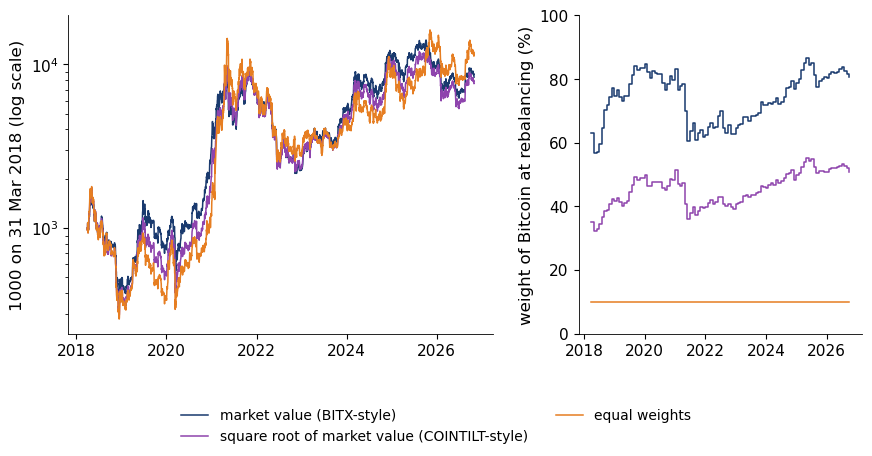

{'cap': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'last': 8341.779259042181, 'cagr': np.float64(28.036339590207284), 'vol': 64.64878972831174, 'n': 3135, 'mdd': -77.94836349178689, 'mdd_peak': '2018-05-05', 'mdd_trough': '2018-12-15', 'btc_last': 80.78321670059611, 'eth_last': 15.76704478360007, 'btc_mean': 74.02246500662035, 'tau_last': '2026-09-30', 'n_last': 10, 'eff_last': 1.4755843834533182}, 'sqrt': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'last': 7624.682150792266, 'cagr': np.float64(26.702494388974806), 'vol': 69.71080542321391, 'n': 3135, 'mdd': -83.39545556707264, 'mdd_peak': '2018-05-05', 'mdd_trough': '2018-12-15', 'btc_last': 50.67434147729545, 'eth_last': 22.387350210549258, 'btc_mean': 45.370506662248694, 'tau_last': '2026-09-30', 'n_last': 10, 'eff_last': 3.145900011444572}, 'equal': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'l

In [23]:
# Three weighting schemes on the same ten coins (the types of Gaman et al.): market value (multi-asset, BITX-style),
# square root of market value (smart beta, COINTILT-style) and equal weights; monthly rebalancing, Laspeyres with a divisor
def weighted_index(scheme, start='2018-03-31', base=1000.0):
    taus = [pd.Timestamp(start)] + [m for m in month_ends(pd.Timestamp(start) + pd.Timedelta(days=1)) if m < pd.Timestamp(END_R)]
    lev, W, I_prev = {}, {}, base
    for j, tau in enumerate(taus):
        end_ = taus[j + 1] if j + 1 < len(taus) else pd.Timestamp(END_R)
        mv0 = MV.loc[tau].dropna()
        x = {'cap': mv0, 'sqrt': np.sqrt(mv0), 'equal': pd.Series(1.0, index=mv0.index)}[scheme]
        w = x / x.sum()
        q = w * I_prev / PX.loc[tau, w.index]                  # units held: weight x index level / price (divisor = 1 here)
        days = pd.date_range(tau + pd.Timedelta(days=1), end_)
        val = (PX.loc[days, w.index] * q).sum(axis=1, min_count=len(w))
        lev.update(val.to_dict()); W[tau] = w
        I_prev = float(val.dropna().iloc[-1])
    s = pd.Series(lev).sort_index(); s.loc[pd.Timestamp(start)] = base
    return s.sort_index(), pd.DataFrame(W).T.reindex(columns=COINS).fillna(0)


WI = {k: weighted_index(k) for k in ['cap', 'sqrt', 'equal']}
lab = {'cap': 'market value (BITX-style)', 'sqrt': 'square root of market value (COINTILT-style)', 'equal': 'equal weights'}
col = {'cap': BLUE, 'sqrt': PURPLE, 'equal': ORANGE}
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
for k, (s, w) in WI.items():
    ax[0].plot(s.index, s, color=col[k], lw=1.1, label=lab[k])
    ax[1].step(w.index, 100 * w['BTC'], where='post', color=col[k], lw=1.1)
ax[0].set_yscale('log'); ax[0].set_ylabel('1000 on 31 Mar 2018 (log scale)')
ax[1].set_ylabel('weight of Bitcoin at rebalancing (%)'); ax[1].set_ylim(0, 100)
legend_below(fig, ncol=2, bottom=0.17)
fix_years(fig); save_fig(fig, 'ba_l3_weighting')
RES['weighting'] = {k: dict(**ann_stats(s), btc_last=100 * float(w['BTC'].iloc[-1]), eth_last=100 * float(w['ETH'].iloc[-1]),
                            btc_mean=100 * float(w['BTC'].mean()), tau_last=f'{w.index[-1]:%Y-%m-%d}',
                            n_last=int((w.iloc[-1] > 0).sum()), eff_last=float(1 / (w.iloc[-1] ** 2).sum()))
                    for k, (s, w) in WI.items()}
r3 = pd.DataFrame({k: logret(s) for k, (s, w) in WI.items()}).dropna()
RES['weighting']['corr'] = dict(cap_sqrt=float(r3['cap'].corr(r3['sqrt'])), cap_equal=float(r3['cap'].corr(r3['equal'])))
print(RES['weighting'])

### 8.2 Bitcoin and USD cash with a protection floor (yield type, LIXX-style)

Our reading of the published rule: $\mathrm{Floor}_t = (0.80 + 0.01)\max_{s\in[t-1\text{y},t]} I_s$; the cash
position is set equal to the floor whenever the gap exceeds 1% of the index, so the index starts with 81% cash and
19% Bitcoin; cash earns the effective federal funds rate (FRED, act/360); a fee of 0.3% is charged on each trade.

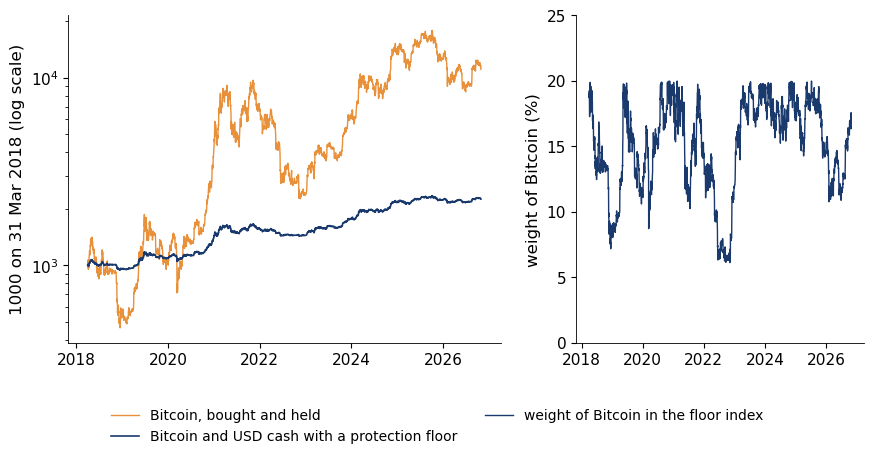

{'floor': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'last': 2256.7661295229636, 'cagr': np.float64(9.947085291190504), 'vol': 9.143486511475068, 'n': 3135, 'mdd': -13.906992360545956, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-21'}, 'btc': {'start': '2018-03-31', 'end': '2026-10-30', 'years': 8.583162217659138, 'first': 1000.0, 'last': 11070.177121224948, 'cagr': np.float64(32.32792463339462), 'vol': 61.58158632929692, 'n': 3135, 'mdd': -76.63456451340275, 'mdd_peak': '2021-11-08', 'mdd_trough': '2022-11-21'}, 'n_reb': 66, 'wb_last': 16.83758245426769, 'wb_mean': 15.081578175888389, 'wb_max': 19.98993262414871, 'wb_max_date': '2020-11-18', 'wb_min': 6.117731214371534, 'effr_mean': 2.703054846938775, 'effr_last': 3.88, 'worst_1y_floor': -13.770231491891405}


In [24]:
# A yield-type index of the LIXX kind: Bitcoin and USD cash with a protection floor (our reading of the published rule)
#   floor_t = (lock-in + buffer) x highest index level of the past 365 days, lock-in 80%, buffer 1%
#   cash target = floor (so the index starts with 81% cash, 19% Bitcoin); rebalance when |floor - cash| > 1% of the index
#   cash earns the effective federal funds rate (FRED, act/360); a fee of 0.3% is charged on the traded amount
btc = PX['BTC'].loc['2018-03-31':END_R].ffill()
effr = pd.read_csv(data_file('indices', 'fed_funds_effective_daily_fred.csv'), parse_dates=['date']).set_index('date')['effr']
effr = effr.reindex(pd.date_range('2017-01-01', END_R)).ffill().loc[btc.index]
LOCK, BUF, FEE = 0.80, 0.01, 0.003
I0 = 1000.0
cash, units = (LOCK + BUF) * I0, (1 - LOCK - BUF) * I0 / btc.iloc[0]
lev, wb, reb = [], [], []
for j, t in enumerate(btc.index):
    if j > 0:
        cash *= 1 + effr.iloc[j - 1] / 100 / 360
    I = cash + units * btc.iloc[j]
    hist = pd.Series(lev + [I], index=btc.index[:j + 1]).loc[t - pd.Timedelta(days=364):t]
    floor = (LOCK + BUF) * hist.max()
    if abs(floor - cash) > BUF * I:
        target_cash = min(floor, I)                            # never more cash than the whole index
        trade = target_cash - cash                             # > 0: sell Bitcoin, < 0: buy Bitcoin
        fee = FEE * abs(trade)
        units -= trade / btc.iloc[j]
        cash = target_cash - fee
        reb.append(t)
        I = cash + units * btc.iloc[j]
    lev.append(I); wb.append(units * btc.iloc[j] / I)
fl = pd.Series(lev, index=btc.index); wb = pd.Series(wb, index=btc.index)
bh = I0 * btc / btc.iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
ax[0].plot(bh.index, bh, color=BTC, lw=1.0, label='Bitcoin, bought and held')
ax[0].plot(fl.index, fl, color=BLUE, lw=1.2, label='Bitcoin and USD cash with a protection floor')
ax[0].set_yscale('log'); ax[0].set_ylabel('1000 on 31 Mar 2018 (log scale)')
ax[1].plot(wb.index, 100 * wb, color=BLUE, lw=1.0, label='weight of Bitcoin in the floor index')
ax[1].set_ylabel('weight of Bitcoin (%)'); ax[1].set_ylim(0, 25)
legend_below(fig, ncol=2, bottom=0.15)
fix_years(fig); save_fig(fig, 'ba_l3_floor')
RES['floor'] = dict(floor=ann_stats(fl), btc=ann_stats(bh), n_reb=len(reb), wb_last=100 * float(wb.iloc[-1]), wb_mean=100 * float(wb.mean()),
                    wb_max=100 * float(wb.max()), wb_max_date=f'{wb.idxmax():%Y-%m-%d}', wb_min=100 * float(wb.min()),
                    effr_mean=float(effr.mean()), effr_last=float(effr.iloc[-1]),
                    worst_1y_floor=100 * float((fl / fl.rolling(365).max() - 1).min()))
print(RES['floor'])

## 9. The numbers of the lecture

All numbers quoted on the slides, as computed above (the same as `Slides/code/l3_indices_results.json`).

In [25]:
import json


def _clean(x):
    if isinstance(x, dict):
        return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return round(float(x), 4)
    if isinstance(x, np.integer):
        return int(x)
    return x


for key in ['conc', 'surv', 'replica', 'crix', 'vcrix', 'lev', 'garch', 'har', 'etf', 'weighting', 'floor']:
    print(key, json.dumps(_clean({k: v for k, v in RES[key].items() if k not in ('table', 'rep_stats', 'crix_stats', 'full')}))[:900])
    print()

conc {"start": "2018-01-01", "end": "2026-10-30", "btc_first": 57.3076, "btc_last": 82.1516, "btc_min": 49.575, "btc_min_date": "2018-01-14", "btc_max": 87.1404, "btc_max_date": "2025-04-21", "eth_last": 14.4919, "top2_last": 96.6435, "hhi_last": 0.6961, "eff_last": 1.4365, "eff_max": 2.97, "eff_max_date": "2018-01-13", "share_btc_above50": 99.845, "mv_total_last": 1889.3511}

surv {"ex_ante": ["BTC", "ETH", "BCH", "ADA", "LTC"], "ex_post": ["BTC", "ETH", "ZEC", "DOGE", "XMR"], "rank_2018": {"BTC": 1, "ETH": 2, "DOGE": 10, "ADA": 4, "LTC": 5, "BCH": 3, "ETC": 8, "XMR": 7, "DASH": 6, "ZEC": 9}, "rank_now": {"BTC": 1, "ETH": 2, "DOGE": 4, "ADA": 6, "LTC": 8, "BCH": 7, "ETC": 9, "XMR": 5, "DASH": 10, "ZEC": 3}, "cap_ante_end": 401.4614, "cap_post_end": 491.4023, "cap_ante_cagr": 17.0543, "cap_post_cagr": 19.766, "eq_ante_end": 183.7148, "eq_post_end": 418.093, "eq_ante_cagr": 7.1335, "eq_post_cagr": 17.5938}

replica {"start": "2018-03-31", "end": "2026-10-30", "n": 3105, "rep_corr": 0.98